# 🐶 DogTranslator — Part 2 (final): models on clean data, before and after data optimisation

**The question:** can a computer tell if a dog is 😠 **angry**, 😄 **happy**, 😌 **relaxed** or 😢 **sad** from a photo?

**The story of this notebook, in 4 acts:**

| Act | What we do | Why |
|---|---|---|
| **0. The clean data** | Load Farah's cleaned dataset and official split (Part 1) | Everybody in the team uses the same data and the same final exam |
| **A. BEFORE** | Train and compare **all 10 models**, from a lazy guesser to a Vision Transformer | Our reference scores on clean data |
| **B. HOW** | Improve the **data**: find wrong labels, balance the emotions, richer augmentation, mirror trick at test time | *Better data often beats a bigger model* |
| **C. AFTER** | Retrain **all 10 models** with the optimised data | Same models, better data |
| **D. BEFORE vs AFTER** | Compare every model, every emotion, explain with Grad-CAM, test on new photos | Did it work, and where? |

> ⏱️ About **1h30–2h** on a free Colab **T4 GPU** (Exécution → Modifier le type d'exécution → GPU T4).
> 💾 **Resumable:** every trained model and score is saved to Drive as soon as it's done. If Colab disconnects, reconnect and **run everything again**: finished models are loaded instead of retrained.

In [1]:
!pip install -q timm scikit-image

In [2]:
import os, re, time, json, random, hashlib, warnings
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image, ImageOps
from tqdm.auto import tqdm
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import transforms
import timm
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
warnings.filterwarnings("ignore")

# ▶▶ EDIT THESE TWO PATHS ◀◀
REPO_URL = "https://github.com/farahbenchoug13/mlproject.git"                                          # Farah's repo (Part 1)
REPO = Path(os.environ.get("DOG_REPO", "/content/mlproject"))
CLEAN_DIR = Path(os.environ.get("DOG_CLEAN_DIR", str(REPO / "data")))                                    # folder that contains splits.csv
OUT = Path(os.environ.get("DOG_OUT", "/content/drive/MyDrive/dogs part 2 jamila/final_clean"))       # where everything is saved

SEED = 42
def seed_all(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
LABELS = ["angry", "happy", "relaxed", "sad"]; L2I = {l: i for i, l in enumerate(LABELS)}
COLORS = {"angry": "#E4572E", "happy": "#F3A712", "relaxed": "#4CB944", "sad": "#2E86AB"}; PALETTE = [COLORS[l] for l in LABELS]
RAW_COUNTS = pd.Series({"angry": 2256, "happy": 4784, "relaxed": 4349, "sad": 4532})     # original Kaggle dataset

TEST = os.environ.get("DOG_TEST") == "1"          # quick self-check mode: leave OFF
PRETRAINED = not TEST
EPOCHS = dict(cnn=1, resnet=1, effnet=1, vit=1, ablation=1) if TEST else dict(cnn=12, resnet=6, effnet=6, vit=4, ablation=4)
VIT_NAME = "vit_tiny_patch16_224" if TEST else "vit_base_patch16_224"
BS = 8 if TEST else 64

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 10})
print("Device:", DEVICE, "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "no GPU 😬 (training will be very slow)")

Device: cpu | no GPU 😬 (training will be very slow)


In [3]:
try:
    from google.colab import drive
    drive.mount("/content/drive"); WORK = Path("/content")
except ImportError:
    WORK = Path(".")
FIG_DIR, TAB_DIR, MODEL_DIR, PROB_DIR, HIST_DIR = (OUT / d for d in ["figures", "tables", "models", "probs", "histories"])
for d in [OUT, FIG_DIR, TAB_DIR, MODEL_DIR, PROB_DIR, HIST_DIR]:
    d.mkdir(parents=True, exist_ok=True)

def _slug(t, d="item"):
    s = re.sub(r"[^a-zA-Z0-9]+", "_", t or "").strip("_").lower()[:70]
    return s or d

if not getattr(plt.show, "_autosave", False):          # every chart is also saved to Drive (figures/)
    _orig_show = plt.show
    def _show_and_save(*a, **k):
        fig = plt.gcf()
        if fig.axes:
            title = fig._suptitle.get_text() if fig._suptitle else next((ax.get_title() for ax in fig.axes if ax.get_title()), "")
            path = FIG_DIR / f"{len(list(FIG_DIR.glob('*.png'))) + 1:03d}_{_slug(title, 'figure')}.png"
            fig.savefig(path, dpi=150, bbox_inches="tight", facecolor="white"); print("💾", path.name)
        return _orig_show(*a, **k)
    _show_and_save._autosave = True; plt.show = _show_and_save
print("Everything will be saved in:", OUT)

Mounted at /content/drive
Everything will be saved in: /content/drive/MyDrive/dogs part 2 jamila/final_clean


In [4]:
# Get Farah's data: clone her repo once (skipped if it is already there)
if not (CLEAN_DIR / "splits.csv").exists():
    !git clone -q --depth 1 {REPO_URL} {REPO}
print("splits.csv found:", (CLEAN_DIR / "splits.csv").exists(), "|", CLEAN_DIR)
!ls {CLEAN_DIR}

splits.csv found: True | /content/mlproject/data
clean  conflicts  duplicates  raw  rejected  splits.csv  to_check


# Before Farah's cleaning: the raw Kaggle data 📦
A quick look at the **original** dataset, so we can show later what cleaning changed.

In [5]:
import kagglehub

# Download latest version
RAW_IN_REPO = REPO / "data" / "raw" / "archive"          # Farah's repo also contains the raw Kaggle images
path = os.environ.get("DOG_DATA_DIR") or (str(RAW_IN_REPO) if RAW_IN_REPO.exists() else kagglehub.dataset_download("devzohaib/dog-emotions-prediction"))

print("Path to dataset files:", path)

Path to dataset files: /content/mlproject/data/raw/archive


In [6]:
import torch
print("GPU:", torch.cuda.is_available())
!find {path} -maxdepth 3 -type d

GPU: False
/content/mlproject/data/raw/archive
/content/mlproject/data/raw/archive/images
/content/mlproject/data/raw/archive/images/angry
/content/mlproject/data/raw/archive/images/happy
/content/mlproject/data/raw/archive/images/relaxed
/content/mlproject/data/raw/archive/images/sad


In [7]:
import os
root = next(p for p in [Path(path) / "images", Path(path)] if all((p / l).is_dir() for l in LABELS))
for c in sorted(os.listdir(root)):
    print(c, len(os.listdir(f"{root}/{c}")))

angry 2256
happy 4784
relaxed 4349
sad 4532


Rule #1 of machine learning: **look at your data before you train anything.** We build a table (a *DataFrame*) with one row per raw image: its path, label, size and whether it opens at all.

In [8]:
EXT = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".gif"}
rows = []
for label in LABELS:
    for p in sorted((root / label).iterdir()):
        if p.suffix.lower() not in EXT:
            continue
        try:
            with Image.open(p) as im:
                w, h, mode = im.size[0], im.size[1], im.mode
            ok = True
        except Exception:
            w = h = 0; mode = None; ok = False
        rows.append(dict(path=str(p), label=label, width=w, height=h, mode=mode, ok=ok, ext=p.suffix.lower()))
df = pd.DataFrame(rows)
print(f"{len(df)} images | {(~df.ok).sum()} broken files")
RAW_COUNTS = df.label.value_counts().reindex(LABELS)          # real raw counts (replaces the fixed numbers above)
df.head()

15921 images | 0 broken files


,path,label,width,height,mode,ok,ext
0,/content/mlproject/data/raw/archive/images/ang...,angry,384,384,RGB,True,.jpg
1,/content/mlproject/data/raw/archive/images/ang...,angry,384,384,RGB,True,.jpg
2,/content/mlproject/data/raw/archive/images/ang...,angry,384,384,RGB,True,.jpg
3,/content/mlproject/data/raw/archive/images/ang...,angry,384,384,RGB,True,.jpg
4,/content/mlproject/data/raw/archive/images/ang...,angry,384,384,RGB,True,.jpg


💾 099_images_per_emotion_raw.png


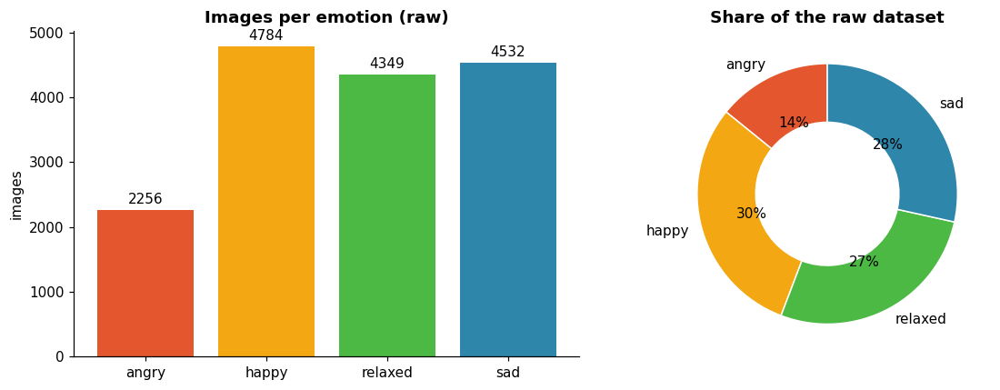

Angry dogs are 47% of the biggest class. Fewer angry dogs, but 100% of the drama.


In [9]:
counts = df.label.value_counts().reindex(LABELS)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
bars = ax[0].bar(LABELS, counts, color=PALETTE)
ax[0].bar_label(bars, padding=3)
ax[0].set_title("Images per emotion (raw)"); ax[0].set_ylabel("images")
ax[1].pie(counts, labels=LABELS, colors=PALETTE, autopct="%1.0f%%", startangle=90,
          wedgeprops=dict(width=0.45, edgecolor="white"))
ax[1].set_title("Share of the raw dataset")
plt.tight_layout(); plt.show()
print(f"Angry dogs are {counts['angry'] / counts.max():.0%} of the biggest class. Fewer angry dogs, but 100% of the drama.")

➡️ **Takeaway:** *angry* is the smallest class. Two things protect us later: **class weights** (a mistake on an angry dog costs more) and **macro F1** as our main score (each emotion counts the same).

### Let's actually look at them

💾 100_raw_labelled_angry.png


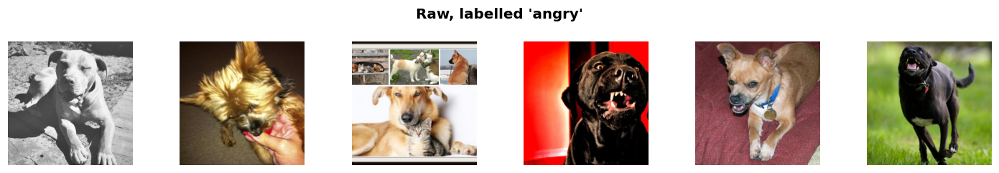

💾 101_raw_labelled_happy.png


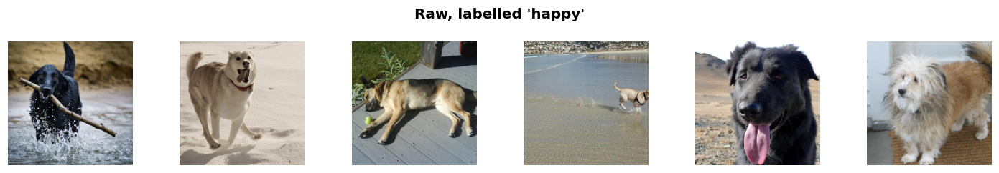

💾 102_raw_labelled_relaxed.png


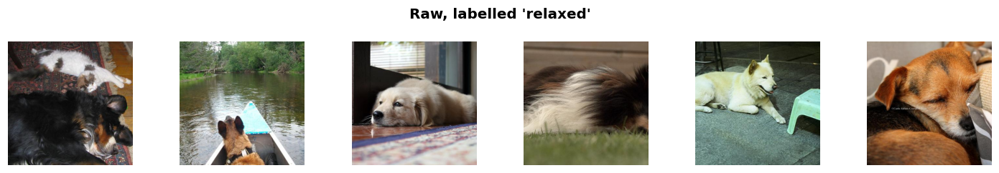

💾 103_raw_labelled_sad.png


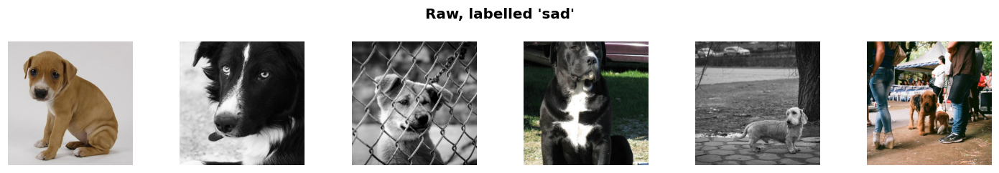

In [10]:
def show_grid(paths, titles=None, ncols=6, size=2.2, suptitle=None, title_colors=None):
    n = len(paths); nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * size, nrows * size), squeeze=False)
    for i, a in enumerate(axes.ravel()):
        a.axis("off")
        if i < n:
            try:
                a.imshow(Image.open(paths[i]).convert("RGB"))
            except Exception:
                a.text(0.5, 0.5, "broken", ha="center")
            if titles:
                a.set_title(titles[i], fontsize=8, color=(title_colors[i] if title_colors else "black"))
    if suptitle: fig.suptitle(suptitle, fontsize=13, fontweight="bold")
    plt.tight_layout(); plt.show()

ok = df[df.ok]
for label in LABELS:
    sample = ok[ok.label == label].sample(min(6, (ok.label == label).sum()), random_state=SEED)
    show_grid(sample.path.tolist(), suptitle=f"Raw, labelled '{label}'")

👀 Are they all dogs? Are they all really showing that emotion? Web-scraped datasets contain cats, cartoons, memes and wrong labels: that's why Part 1 cleaned the data.

### Image sizes and formats (raw)

💾 104_image_sizes_raw.png


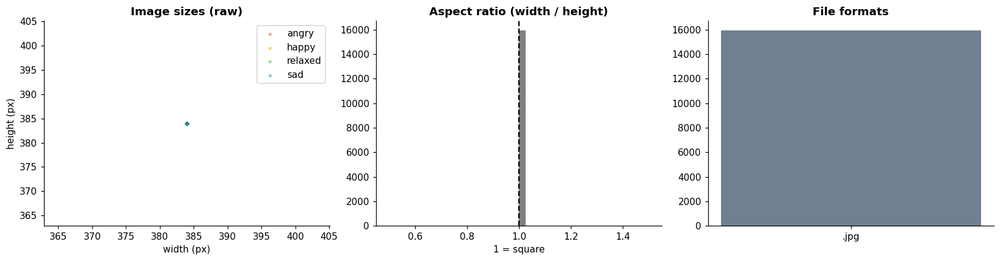

          count   mean  std    min    25%    50%    75%    max
width   15921.0  384.0  0.0  384.0  384.0  384.0  384.0  384.0
height  15921.0  384.0  0.0  384.0  384.0  384.0  384.0  384.0


In [11]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
s = ok.sample(min(3000, len(ok)), random_state=SEED)
for l in LABELS:
    d = s[s.label == l]
    ax[0].scatter(d.width, d.height, s=6, alpha=0.4, color=COLORS[l], label=l)
ax[0].set_xlabel("width (px)"); ax[0].set_ylabel("height (px)"); ax[0].set_title("Image sizes (raw)"); ax[0].legend()
ax[1].hist((ok.width / ok.height).clip(0, 3), bins=40, color="gray")
ax[1].axvline(1, color="k", ls="--"); ax[1].set_title("Aspect ratio (width / height)"); ax[1].set_xlabel("1 = square")
fmt = ok.ext.value_counts()
ax[2].bar(fmt.index, fmt.values, color="slategray"); ax[2].set_title("File formats")
plt.tight_layout(); plt.show()
print(ok[["width", "height"]].describe().round(0).T)

➡️ All raw images are **384×384, square, .jpg**: the dataset author already standardized them.

### Are there duplicates? 🕵️
A fingerprint (MD5 hash) of each file: identical files have the same fingerprint. Duplicates are dangerous (the same photo in train and test makes the score lie), and the **same photo with two different labels** is even worse.

hashing:   0%|          | 0/15921 [00:00<?, ?it/s]

Exact duplicate files: 79
Same photo with DIFFERENT labels: 47 groups 🤯
💾 105_same_photo_different_labels_who_s_right.png


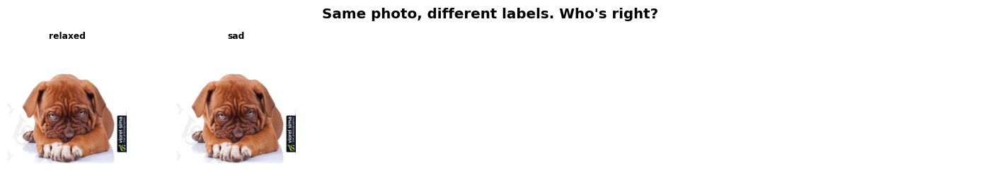

In [12]:
def md5(p):
    with open(p, "rb") as f:
        return hashlib.md5(f.read()).hexdigest()

with ThreadPoolExecutor(8) as ex:
    df["md5"] = list(tqdm(ex.map(md5, df.path), total=len(df), desc="hashing"))

dup_groups = df[df.duplicated("md5", keep=False)].groupby("md5")
n_dup_raw = df.duplicated("md5").sum()
conflicts = [g for _, g in dup_groups if g.label.nunique() > 1]
print(f"Exact duplicate files: {n_dup_raw}")
print(f"Same photo with DIFFERENT labels: {len(conflicts)} groups 🤯")
if conflicts:
    g = conflicts[0]
    show_grid(g.path.tolist()[:6], titles=g.label.tolist()[:6], suptitle="Same photo, different labels. Who's right?")

➡️ These problems (cats, dog-less photos, duplicates, conflicting labels) are exactly what Farah's cleaning (Part 1) handled. Now we switch to **her clean data**.

# Act 0 — The clean data 🧹

In Part 1, Farah cleaned the Kaggle dataset:
- **YOLO** kept photos with one clear dog and **cropped** it; cats and dog-less photos were **rejected**; uncertain photos (several dogs, tiny dogs) were **set aside**;
- a **perceptual hash** removed near-duplicates and photos that had **two different labels**;
- a **stratified 70/15/15 split** (seed 42) was saved in `splits.csv`. It's the **official exam** for the whole team.

In [13]:
sp = pd.read_csv(CLEAN_DIR / "splits.csv").rename(columns={"filepath": "path"})
sp["label"] = sp.label.str.lower()

def resolve(p):
    parts = Path(p).parts
    for cand in [Path(p)] + [CLEAN_DIR.joinpath(*parts[i:]) for i in range(len(parts))]:
        if cand.exists():
            return str(cand)
    return None

sp["path"] = [resolve(p) for p in tqdm(sp.path, desc="finding files")]
missing = int(sp.path.isna().sum())
data = sp.dropna(subset=["path"]).reset_index(drop=True)
print(f"{len(data)} clean images found ({missing} paths not found)")
assert missing < 0.01 * len(sp), "Many files not found: check CLEAN_DIR"

def info(p):
    try:
        with Image.open(p) as im: return im.size[0], im.size[1], True
    except Exception:
        return 0, 0, False
with ThreadPoolExecutor(8) as ex:
    data[["width", "height", "ok"]] = pd.DataFrame(list(tqdm(ex.map(info, data.path), total=len(data), desc="checking")))
data = data[data.ok].reset_index(drop=True)
data["y"] = data.label.map(L2I)
data.head()

finding files:   0%|          | 0/13238 [00:00<?, ?it/s]

13238 clean images found (0 paths not found)


checking:   0%|          | 0/13238 [00:00<?, ?it/s]

,path,label,split,width,height,ok,y
0,/content/mlproject/data/clean/angry/100035066_...,angry,train,242,307,True,0
1,/content/mlproject/data/clean/angry/1007148341...,angry,test,184,302,True,0
2,/content/mlproject/data/clean/angry/1007803967...,angry,train,384,384,True,0
3,/content/mlproject/data/clean/angry/1013147458...,angry,train,339,381,True,0
4,/content/mlproject/data/clean/angry/1020621584...,angry,test,318,375,True,0


### Raw vs clean: what did cleaning change?

💾 106_images_per_emotion_raw_vs_clean.png


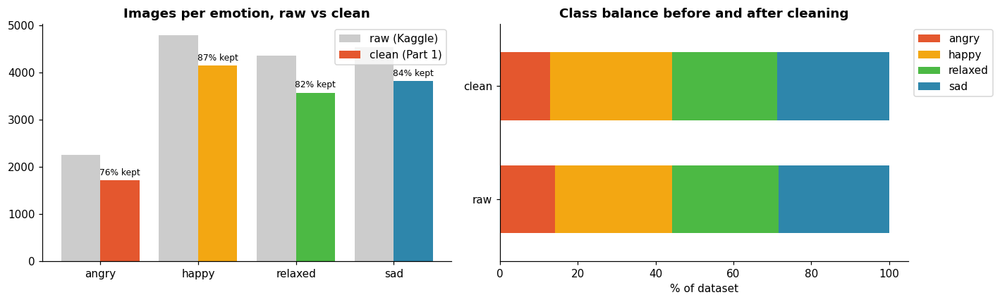

💾 107_share_of_the_clean_dataset.png


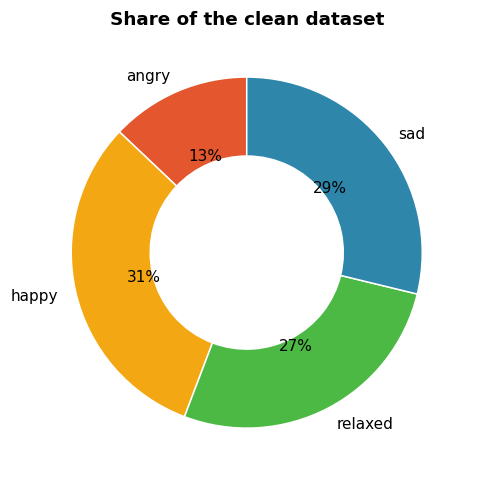

Total: 15921 raw → 13238 clean (83% kept)


In [14]:
clean_counts = data.label.value_counts().reindex(LABELS)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
x = np.arange(4)
ax[0].bar(x - 0.2, RAW_COUNTS, 0.4, color="#cccccc", label="raw (Kaggle)")
b = ax[0].bar(x + 0.2, clean_counts, 0.4, color=PALETTE, label="clean (Part 1)")
ax[0].bar_label(b, labels=[f"{c/r:.0%} kept" for c, r in zip(clean_counts, RAW_COUNTS)], padding=3, fontsize=8)
ax[0].set_xticks(x, LABELS); ax[0].legend(); ax[0].set_title("Images per emotion, raw vs clean")
share = pd.DataFrame({"raw": RAW_COUNTS / RAW_COUNTS.sum(), "clean": clean_counts / clean_counts.sum()}) * 100
share.T.plot.barh(stacked=True, color=PALETTE, ax=ax[1], width=0.6)
ax[1].set_xlabel("% of dataset"); ax[1].set_title("Class balance before and after cleaning"); ax[1].legend(bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.pie(clean_counts, labels=LABELS, colors=PALETTE, autopct="%1.0f%%", startangle=90, wedgeprops=dict(width=0.45, edgecolor="white"))
ax.set_title("Share of the clean dataset"); plt.tight_layout(); plt.show()
print(f"Total: {RAW_COUNTS.sum()} raw → {len(data)} clean ({len(data)/RAW_COUNTS.sum():.0%} kept)")

➡️ Angry lost the most photos (snarling close-ups are hard for YOLO to recognise as dogs), so **angry is now even rarer**. Keep an eye on angry in every result.

### The official split (train / validation / test)
- **train** = the exercises the models study;
- **validation** = mock exams, used to pick the best epoch and to **decide** which data optimisations to keep;
- **test** = the final exam, used **only to report** scores.

💾 108_same_emotion_mix_in_every_split_stratified.png


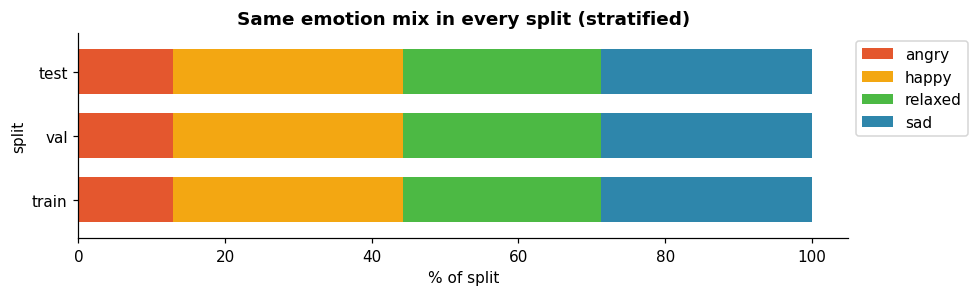

label  angry  happy  relaxed   sad  total
split                                    
train   1198   2901     2499  2668   9266
val      256    622      536   572   1986
test     257    621      536   572   1986


In [15]:
tr, va, te = (np.where(data.split.values == s)[0] for s in ["train", "val", "test"])
tab = pd.crosstab(data.split, data.label).reindex(["train", "val", "test"])[LABELS]
ax = (tab.div(tab.sum(1), axis=0) * 100).plot.barh(stacked=True, color=PALETTE, figsize=(9, 2.8), width=0.7)
ax.set_xlabel("% of split"); ax.set_title("Same emotion mix in every split (stratified)"); ax.legend(bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()
print(tab.assign(total=tab.sum(1)))
data[["path", "label", "split"]].to_csv(OUT / "split_used.csv", index=False)

### Let's look at the clean dogs

In [16]:
for l in LABELS:
    s = data[data.label == l].sample(min(7, (data.label == l).sum()), random_state=SEED)
    show_grid(s.path.tolist(), suptitle=f"Clean '{l}' dogs")

Output hidden; open in https://colab.research.google.com to view.

### Image sizes (crops are no longer all 384×384) and a duplicate check
The raw dataset was all 384×384. Farah's crops have **different sizes**, so we resize everything to the same size later. We also check that no identical photo is left (it should be ~0 after her cleaning).

💾 113_crop_sizes_clean.png


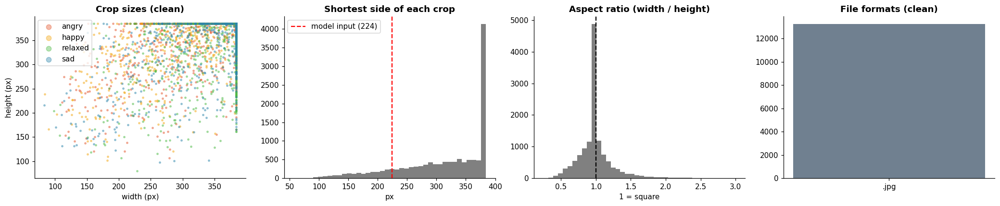

          count   mean   std   min    25%    50%    75%    max
width   13238.0  330.0  70.0  71.0  292.0  366.0  384.0  384.0
height  13238.0  339.0  64.0  57.0  311.0  375.0  384.0  384.0


hashing:   0%|          | 0/13238 [00:00<?, ?it/s]

Exact duplicates left: 0 | same photo with different labels: 0  (Part 1 did its job if these are ~0)


In [17]:
fig, ax = plt.subplots(1, 4, figsize=(19, 4))
for l in LABELS:
    d = data[data.label == l].sample(min(800, (data.label == l).sum()), random_state=SEED)
    ax[0].scatter(d.width, d.height, s=5, alpha=0.4, color=COLORS[l], label=l)
ax[0].set_xlabel("width (px)"); ax[0].set_ylabel("height (px)"); ax[0].set_title("Crop sizes (clean)"); ax[0].legend(markerscale=3)
ax[1].hist(np.minimum(data.width, data.height), bins=40, color="gray"); ax[1].axvline(224, color="red", ls="--", label="model input (224)")
ax[1].set_title("Shortest side of each crop"); ax[1].set_xlabel("px"); ax[1].legend()
ax[2].hist((data.width / data.height).clip(0, 3), bins=40, color="gray"); ax[2].axvline(1, color="k", ls="--")
ax[2].set_title("Aspect ratio (width / height)"); ax[2].set_xlabel("1 = square")
fmt = data.path.str.extract(r"(\.[A-Za-z]+)$")[0].str.lower().value_counts()
ax[3].bar(fmt.index, fmt.values, color="slategray"); ax[3].set_title("File formats (clean)")
plt.tight_layout(); plt.show()
print(data[["width", "height"]].describe().round(0).T)

def md5(p):
    with open(p, "rb") as f: return hashlib.md5(f.read()).hexdigest()
with ThreadPoolExecutor(8) as ex:
    data["md5"] = list(tqdm(ex.map(md5, data.path), total=len(data), desc="hashing"))
n_dup = int(data.duplicated("md5").sum())
n_conf = int((data.groupby("md5").label.nunique() > 1).sum())
print(f"Exact duplicates left: {n_dup} | same photo with different labels: {n_conf}  (Part 1 did its job if these are ~0)")

In [18]:
# Speed trick: save small copies once (max 288 px), so training reads small files
CACHE = WORK / "resized_final"
def shrink(args):
    i, p = args
    dst = CACHE / f"{i:05d}.jpg"
    if not dst.exists():
        dst.parent.mkdir(parents=True, exist_ok=True)
        im = ImageOps.exif_transpose(Image.open(p)).convert("RGB"); im.thumbnail((288, 288)); im.save(dst, quality=92)
    return str(dst)
with ThreadPoolExecutor(8) as ex:
    data["small"] = list(tqdm(ex.map(shrink, zip(data.index, data.path)), total=len(data), desc="resizing"))
PATHS, Y = data.small.values, data.y.values
print("Ready:", len(data), "images | train", len(tr), "| val", len(va), "| test", len(te))

resizing:   0%|          | 0/13238 [00:00<?, ?it/s]

Ready: 13238 images | train 9266 | val 1986 | test 1986


## Images are numbers 🔢
A computer doesn't "see" a dog: it sees a grid of **pixels**, each with 3 numbers (Red, Green, Blue) from 0 to 255. A 224×224 photo = **150,528 numbers**.

Shape: (288, 288, 3) → (height, width, channels)
💾 114_what_we_see.png


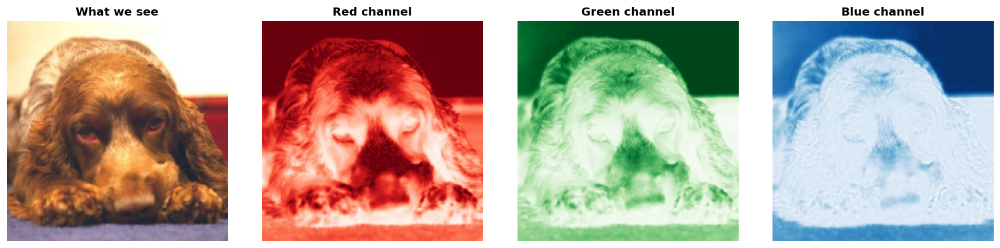

In [19]:
ex_row = data[data.label == "happy"].iloc[0]
img = np.array(Image.open(ex_row.small).convert("RGB"))
print("Shape:", img.shape, "→ (height, width, channels)")

fig, ax = plt.subplots(1, 4, figsize=(15, 3.6))
ax[0].imshow(img); ax[0].set_title("What we see")
for i, (name, cmap) in enumerate([("Red", "Reds"), ("Green", "Greens"), ("Blue", "Blues")]):
    ax[i + 1].imshow(img[:, :, i], cmap=cmap); ax[i + 1].set_title(f"{name} channel")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

💾 115_grayscale_1_number_per_pixel.png


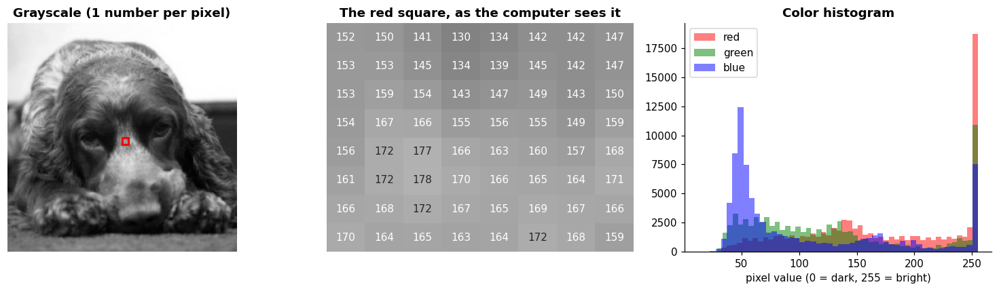

In [20]:
# Zoom into an 8x8 patch: these are the actual numbers
gray = np.array(Image.open(ex_row.small).convert("L"))
cy, cx = gray.shape[0] // 2, gray.shape[1] // 2
patch = gray[cy:cy + 8, cx:cx + 8]
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].imshow(gray, cmap="gray"); ax[0].add_patch(plt.Rectangle((cx, cy), 8, 8, fill=False, color="red", lw=2))
ax[0].set_title("Grayscale (1 number per pixel)"); ax[0].axis("off")
sns.heatmap(patch, annot=True, fmt="d", cmap="gray", cbar=False, ax=ax[1], vmin=0, vmax=255)
ax[1].set_title("The red square, as the computer sees it"); ax[1].axis("off")
for i, c in enumerate(["red", "green", "blue"]):
    ax[2].hist(img[:, :, i].ravel(), bins=50, color=c, alpha=0.5, label=c)
ax[2].set_title("Color histogram"); ax[2].set_xlabel("pixel value (0 = dark, 255 = bright)"); ax[2].legend()
plt.tight_layout(); plt.show()

loading 64x64:   0%|          | 0/13238 [00:00<?, ?it/s]

💾 116_brightness_per_emotion.png


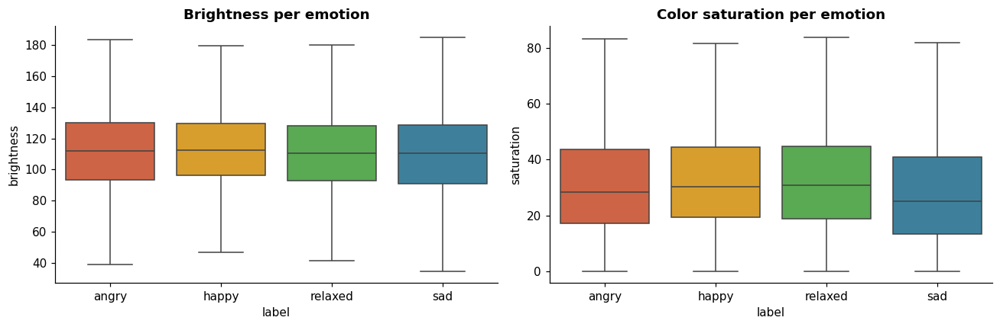

X64: (13238, 64, 64, 3) (163 MB)
💾 117_the_average_dog_per_emotion_a_blurry_ghost.png


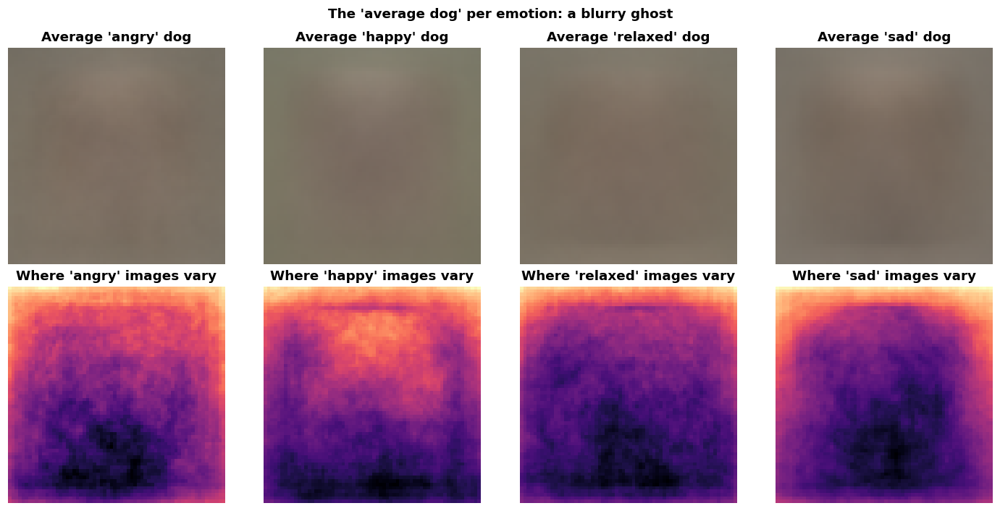

In [21]:
def load_small(p, size=64):
    return np.asarray(Image.open(p).convert("RGB").resize((size, size)))
with ThreadPoolExecutor(8) as ex:
    X64 = np.stack(list(tqdm(ex.map(load_small, PATHS), total=len(PATHS), desc="loading 64x64")))
data["brightness"] = X64.mean(axis=(1, 2, 3))
data["saturation"] = (X64.max(axis=3).astype(int) - X64.min(axis=3)).mean(axis=(1, 2))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=data, x="label", y="brightness", order=LABELS, palette=PALETTE, ax=ax[0], showfliers=False); ax[0].set_title("Brightness per emotion")
sns.boxplot(data=data, x="label", y="saturation", order=LABELS, palette=PALETTE, ax=ax[1], showfliers=False); ax[1].set_title("Color saturation per emotion")
plt.tight_layout(); plt.show()

print("X64:", X64.shape, f"({X64.nbytes / 1e6:.0f} MB)")
fig, ax = plt.subplots(2, 4, figsize=(13, 6.5))
for i, l in enumerate(LABELS):
    sel = X64[Y == i].astype(np.float32)
    ax[0, i].imshow(sel.mean(0).astype(np.uint8)); ax[0, i].set_title(f"Average '{l}' dog")
    ax[1, i].imshow(sel.std(0).mean(-1), cmap="magma"); ax[1, i].set_title(f"Where '{l}' images vary")
for a in ax.ravel(): a.axis("off")
plt.suptitle("The 'average dog' per emotion: a blurry ghost", fontweight="bold"); plt.tight_layout(); plt.show()

➡️ Colors and the average image barely change between emotions. Emotions live in **shapes** (ears, mouth, eyes, posture), so we need smarter features.

## Classic computer vision: hand-made features 🛠️
Blur removes noise, **edge detectors** (Sobel, Canny) find outlines, **histogram equalization** fixes dark photos, and **HOG** describes shapes by counting edge directions in small cells.

💾 118_hand_made_image_features.png


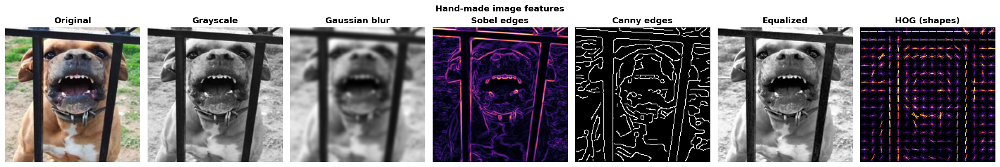

HOG turns this image into a vector of 8100 numbers describing its shapes.


In [22]:
from skimage import feature, filters, exposure, color as skcolor
rgb = np.asarray(Image.open(data[data.label == "angry"].iloc[0].small).convert("RGB").resize((192, 192)))
g = skcolor.rgb2gray(rgb)
hog_vec, hog_img = feature.hog(g, orientations=9, pixels_per_cell=(12, 12), cells_per_block=(2, 2), visualize=True)
steps = [("Original", rgb, None), ("Grayscale", g, "gray"), ("Gaussian blur", filters.gaussian(g, sigma=2), "gray"),
         ("Sobel edges", filters.sobel(g), "magma"), ("Canny edges", feature.canny(g, sigma=2), "gray"),
         ("Equalized", exposure.equalize_hist(g), "gray"), ("HOG (shapes)", exposure.rescale_intensity(hog_img, in_range=(0, hog_img.max() / 3)), "inferno")]
fig, ax = plt.subplots(1, 7, figsize=(20, 3.4))
for a, (t, im, cm) in zip(ax, steps):
    a.imshow(im, cmap=cm); a.set_title(t); a.axis("off")
plt.suptitle("Hand-made image features", fontweight="bold"); plt.tight_layout(); plt.show()
print(f"HOG turns this image into a vector of {hog_vec.size} numbers describing its shapes.")

## Data augmentation: free extra data 🎁
A dog flipped left-right is still the same dog with the same emotion. By randomly **flipping, rotating, cropping and changing colors** during training, we show the model "new" images for free. Here is **one** image, augmented 8 times:

💾 119_original.png


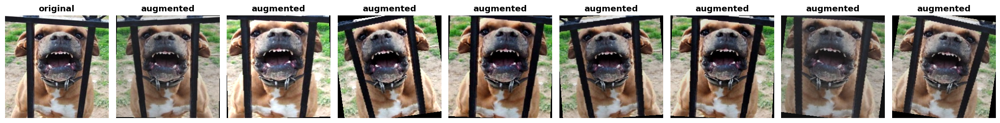

In [23]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
_aug = transforms.Compose([transforms.RandomResizedCrop(224, scale=(0.7, 1.0)), transforms.RandomHorizontalFlip(),
                           transforms.RandomRotation(10), transforms.ColorJitter(0.2, 0.2, 0.2), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
pil = Image.open(PATHS[0]).convert("RGB")
fig, ax = plt.subplots(1, 9, figsize=(20, 2.6))
ax[0].imshow(pil.resize((224, 224))); ax[0].set_title("original", fontweight="bold")
for a in ax[1:]:
    a.imshow((_aug(pil).permute(1, 2, 0).numpy() * STD + MEAN).clip(0, 1)); a.set_title("augmented")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

## 🧰 Shared tools (training, scoring, saving)
This cell defines the tools used by every experiment, so all models are trained and scored **the same way**:
- `make_tf`: image transforms (`basic` or `strong` augmentation for training, plain resize for evaluation);
- `train`: trains a network and keeps the epoch with the **best validation macro F1**. Options: which training photos, augmentation type, class balancing, test-time augmentation;
- `record`: scores a model on the **test set** (accuracy, macro F1, F1 per emotion) and **saves it to Drive at once**.

In [24]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
def make_tf(size=224, kind="eval"):
    norm = [transforms.ToTensor(), transforms.Normalize(MEAN, STD)]
    if kind == "eval":
        return transforms.Compose([transforms.Resize((size, size))] + norm)
    base = [transforms.RandomResizedCrop(size, scale=(0.7, 1.0)), transforms.RandomHorizontalFlip()]
    if kind == "basic":
        return transforms.Compose(base + [transforms.RandomRotation(10), transforms.ColorJitter(0.2, 0.2, 0.2)] + norm)
    return transforms.Compose(base + [transforms.TrivialAugmentWide()] + norm + [transforms.RandomErasing(p=0.25, scale=(0.02, 0.15))])
def denorm(t): return (t.permute(1, 2, 0).numpy() * STD + MEAN).clip(0, 1)

class DS(Dataset):
    def __init__(self, idx, tf): self.idx, self.tf = np.asarray(idx), tf
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        j = self.idx[i]; return self.tf(Image.open(PATHS[j]).convert("RGB")), int(Y[j])

@torch.no_grad()
def predict(model, idx, size=224, tta=False):
    dl = DataLoader(DS(idx, make_tf(size)), batch_size=BS * 2, num_workers=2)
    model.eval(); out = []
    for x, _ in dl:
        x = x.to(DEVICE)
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
            p = model(x).float().softmax(1)
            if tta: p = (p + model(torch.flip(x, dims=[3])).float().softmax(1)) / 2
        out.append(p.cpu())
    return torch.cat(out).numpy()

# ---- results saved to Drive immediately (resumable) ----
RES_CSV = OUT / "all_results.csv"
RESULTS = pd.read_csv(RES_CSV).to_dict("records") if RES_CSV.exists() else []
def _key(name): return _slug(name, "model")
def record(name, family, stage, probs, train_time, n_params=None, val_f1=np.nan, extra=None):
    global RESULTS
    yt, yp = Y[te], probs.argmax(1)
    per = f1_score(yt, yp, average=None, labels=range(4))
    row = dict(model=name, base=name.rsplit(" [", 1)[0], family=family, stage=stage, accuracy=accuracy_score(yt, yp),
               macro_f1=f1_score(yt, yp, average="macro"), val_macro_f1=val_f1, train_time_s=train_time, params=n_params,
               **{f"f1_{l}": v for l, v in zip(LABELS, per)}, **(extra or {}))
    RESULTS = [r for r in RESULTS if r["model"] != name] + [row]
    pd.DataFrame(RESULTS).to_csv(RES_CSV, index=False); np.save(PROB_DIR / f"{_key(name)}.npy", probs)
    print(f"✅ {name:42s} test acc {row['accuracy']:.3f} | macro F1 {row['macro_f1']:.3f} | angry F1 {per[0]:.2f}")
def probs_of(name): return np.load(PROB_DIR / f"{_key(name)}.npy")
def hist_of(name): return pd.read_csv(HIST_DIR / f"{_key(name)}.csv")
def done(name): return any(r["model"] == name for r in RESULTS) and (MODEL_DIR / f"{_key(name)}.pt").exists()
def onehot(pred): return np.eye(4)[pred]

def train(make_model, name, stage, epochs, lr, size=224, bs=BS, train_idx=None, aug="basic", balance="weights", tta=False, family="deep learning"):
    ckpt = MODEL_DIR / f"{_key(name)}.pt"
    model = make_model().to(DEVICE)
    if done(name):
        model.load_state_dict(torch.load(ckpt, map_location=DEVICE)); print(f"⏩ {name}: already trained, loaded from Drive"); return model
    seed_all(); train_idx = tr if train_idx is None else np.asarray(train_idx)
    ytr = Y[train_idx]; cnt = np.bincount(ytr, minlength=4); ds = DS(train_idx, make_tf(size, aug))
    if balance == "sampler":
        sampler = WeightedRandomSampler(torch.tensor(1.0 / cnt[ytr], dtype=torch.double), len(ds), replacement=True)
        dl = DataLoader(ds, batch_size=bs, sampler=sampler, num_workers=2, pin_memory=True)
        crit = nn.CrossEntropyLoss(label_smoothing=0.1)
    else:
        w = torch.tensor(cnt.sum() / (4 * np.maximum(cnt, 1)), dtype=torch.float32, device=DEVICE)
        dl = DataLoader(ds, batch_size=bs, shuffle=True, num_workers=2, pin_memory=True)
        crit = nn.CrossEntropyLoss(weight=w, label_smoothing=0.1)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=epochs * len(dl))
    scaler = torch.amp.GradScaler("cuda", enabled=DEVICE.type == "cuda")
    hist, best, t0 = [], -1, time.time()
    for ep in range(1, epochs + 1):
        model.train(); losses, correct, seen = [], 0, 0
        for x, y in tqdm(dl, desc=f"{name} ep {ep}/{epochs}", leave=False):
            x, y = x.to(DEVICE), y.to(DEVICE)
            with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
                out = model(x); loss = crit(out, y)
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            losses.append(loss.item()); correct += (out.argmax(1) == y).sum().item(); seen += len(y)
        pv = predict(model, va, size)
        vloss = F.nll_loss(torch.log(torch.tensor(pv) + 1e-8), torch.tensor(Y[va])).item()
        vf1 = f1_score(Y[va], pv.argmax(1), average="macro")
        hist.append(dict(epoch=ep, train_loss=np.mean(losses), train_acc=correct / seen, val_loss=vloss,
                         val_acc=accuracy_score(Y[va], pv.argmax(1)), val_f1=vf1))
        print(f"  epoch {ep}: train acc {correct/seen:.3f} | val acc {hist[-1]['val_acc']:.3f} | val F1 {vf1:.3f}")
        if vf1 > best:
            best = vf1; torch.save(model.state_dict(), ckpt)
    pd.DataFrame(hist).to_csv(HIST_DIR / f"{_key(name)}.csv", index=False)
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    record(name, family, stage, predict(model, te, size, tta), time.time() - t0, sum(p.numel() for p in model.parameters()), best,
           dict(train_images=len(train_idx), aug=aug, balance=balance, tta=tta))
    return model

def plot_history(name):
    h = hist_of(name)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
    ax[0].plot(h.epoch, h.train_loss, "o-", label="train"); ax[0].plot(h.epoch, h.val_loss, "o-", label="validation")
    ax[0].set_title(f"{name}: loss"); ax[0].legend(); ax[0].set_xlabel("epoch")
    ax[1].plot(h.epoch, h.train_acc, "o-", label="train acc"); ax[1].plot(h.epoch, h.val_acc, "o-", label="val acc")
    ax[1].plot(h.epoch, h.val_f1, "s--", label="val macro F1"); ax[1].set_title(f"{name}: scores"); ax[1].legend(); ax[1].set_xlabel("epoch")
    plt.tight_layout(); plt.show()

def plot_cms(names, ncols=4, title=None):
    nrows = int(np.ceil(len(names) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.7 * nrows), squeeze=False)
    for a, n in zip(axes.ravel(), names):
        cm = confusion_matrix(Y[te], probs_of(n).argmax(1), labels=range(4), normalize="true")
        sns.heatmap(cm, annot=True, fmt=".0%", cmap="Blues", cbar=False, ax=a, xticklabels=LABELS, yticklabels=LABELS, vmin=0, vmax=1)
        a.set_title(n, fontsize=9); a.set_xlabel("predicted"); a.set_ylabel("true")
    for a in axes.ravel()[len(names):]: a.axis("off")
    if title: plt.suptitle(title, fontweight="bold")
    plt.tight_layout(); plt.show()

class TinyCNN(nn.Module):
    def __init__(self, n=4):
        super().__init__()
        def block(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n))
    def forward(self, x): return self.head(self.features(x))

DEEP = {  # base name -> (model factory, epochs, learning rate, image size, batch size)
    "TinyCNN (from scratch)": (lambda: TinyCNN(), EPOCHS["cnn"], 3e-3, 128, BS),
    "ResNet50 fine-tuned": (lambda: timm.create_model("resnet50", pretrained=PRETRAINED, num_classes=4), EPOCHS["resnet"], 5e-4, 224, BS),
    "EfficientNet-B0 fine-tuned": (lambda: timm.create_model("efficientnet_b0", pretrained=PRETRAINED, num_classes=4), EPOCHS["effnet"], 1e-3, 224, BS),
    "ViT fine-tuned": (lambda: timm.create_model(VIT_NAME, pretrained=PRETRAINED, num_classes=4), EPOCHS["vit"], 5e-5, 224, 8 if TEST else 32),
}
_cnt = np.bincount(Y[tr], minlength=4)
print("Class weights (angry costs more):", dict(zip(LABELS, (_cnt.sum() / (4 * _cnt)).round(2))))

def load_trained(base, stage):
    mk, ep, lr, size, bs = DEEP[base]
    m = mk().to(DEVICE); m.load_state_dict(torch.load(MODEL_DIR / f"{_key(base + ' [' + stage + ']')}.pt", map_location=DEVICE))
    return m.eval(), size
print("Tools ready.", f"{len(RESULTS)} results already saved from a previous run." if RESULTS else "")

Class weights (angry costs more): {'angry': np.float64(1.93), 'happy': np.float64(0.8), 'relaxed': np.float64(0.93), 'sad': np.float64(0.87)}
Tools ready. 24 results already saved from a previous run.


# Act A — BEFORE data optimisation: all 10 models 📏

Same recipe as our first experiments, now on the **clean** data:
- **classic ML** on hand-made features: a lazy guesser, k-NN, logistic regression, random forest, linear SVM;
- **deep learning**: a small CNN from scratch, ResNet-50 as a frozen feature machine, and three fine-tuned pretrained networks (ResNet-50, EfficientNet-B0, ViT).

### How we score
- **Accuracy** = % correct (misleading with imbalanced classes);
- **Macro F1** = F1 per emotion, averaged: each emotion counts the same, so a model that ignores angry dogs is punished. **Our main score**;
- **Confusion matrix** = who gets confused with whom.

HOG:   0%|          | 0/13238 [00:00<?, ?it/s]

features → pixels (13238, 3072) | color histogram (13238, 64) | HOG (13238, 1764)
✅ Dummy (lazy guesser) [before]              test acc 0.313 | macro F1 0.119 | angry F1 0.00
✅ k-NN on pixels [before]                    test acc 0.314 | macro F1 0.275 | angry F1 0.11
✅ LogReg on pixels [before]                  test acc 0.293 | macro F1 0.280 | angry F1 0.17
✅ Random forest on colors [before]           test acc 0.388 | macro F1 0.307 | angry F1 0.04
✅ Linear SVM on HOG [before]                 test acc 0.329 | macro F1 0.304 | angry F1 0.15
💾 120_classic_ml_who_gets_confused_with_whom.png


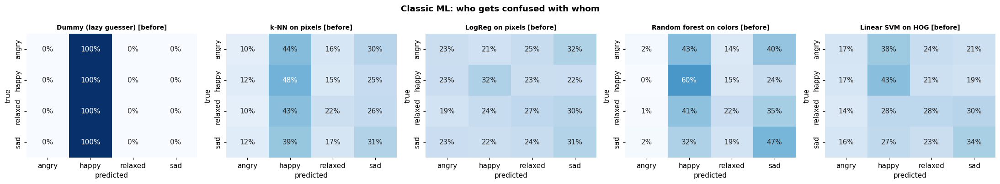

In [25]:
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

X32 = np.stack([np.asarray(Image.fromarray(x).resize((32, 32))) for x in X64]).reshape(len(X64), -1) / 255.0
def color_hist(x):
    q = (x // 64).reshape(-1, 3); h = np.bincount(q[:, 0] * 16 + q[:, 1] * 4 + q[:, 2], minlength=64); return h / h.sum()
XHIST = np.stack([color_hist(x) for x in X64])
XHOG = np.stack([feature.hog(skcolor.rgb2gray(x), orientations=9, pixels_per_cell=(8, 8), cells_per_block=(2, 2)) for x in tqdm(X64, desc="HOG")])
print("features → pixels", X32.shape, "| color histogram", XHIST.shape, "| HOG", XHOG.shape)

def classic_models():
    return [("Dummy (lazy guesser)", DummyClassifier(strategy="most_frequent"), X32),
            ("k-NN on pixels", make_pipeline(StandardScaler(), KNeighborsClassifier(5)), X32),
            ("LogReg on pixels", make_pipeline(StandardScaler(), LogisticRegression(max_iter=300, class_weight="balanced")), X32),
            ("Random forest on colors", RandomForestClassifier(300, class_weight="balanced", n_jobs=-1, random_state=SEED), XHIST),
            ("Linear SVM on HOG", make_pipeline(StandardScaler(), LinearSVC(C=0.01, class_weight="balanced")), XHOG)]

def run_classic(stage, train_idx):
    for base, model, X in classic_models():
        name = f"{base} [{stage}]"
        t = time.time(); model.fit(X[train_idx], Y[train_idx]); dt = time.time() - t
        record(name, "classic ML", stage, onehot(model.predict(X[te])), dt, extra=dict(train_images=len(train_idx)))

run_classic("before", tr)
plot_cms([f"{b} [before]" for b, _, _ in classic_models()], ncols=5, title="Classic ML: who gets confused with whom")

➡️ **What do we learn?**
- The **Dummy** sets the floor: the score you get by knowing nothing.
- Models on **raw pixels** and **colors** barely beat it: a pixel doesn't know it's part of an ear.
- **HOG** (shapes) usually does a bit better: shapes matter more than colors for emotions.
- Everybody struggles: hand-made features hit their limit, so it's time for models that **learn their own features**.

### PCA: can we see the emotions in 2D?
PCA compresses the 3,072 pixel numbers into a few main "directions". If emotions were easy, we'd see 4 separate color clouds.

💾 121_test_images_on_the_first_2_pca_directions.png


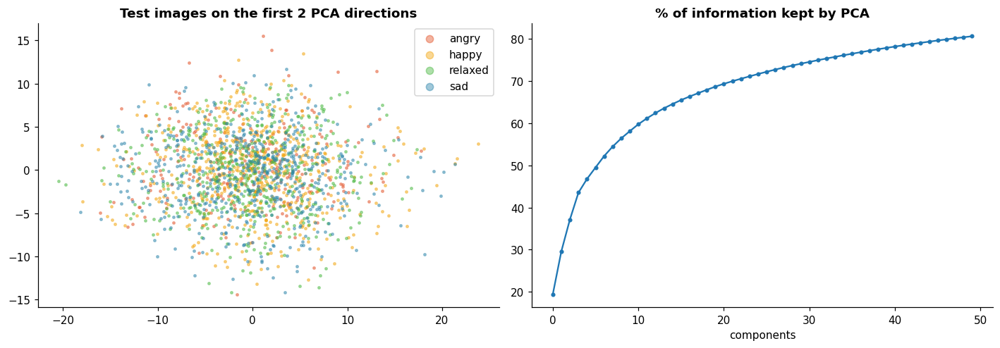

💾 122_eigendogs_the_main_pixel_patterns_lighting_and_background_not_emotions.png


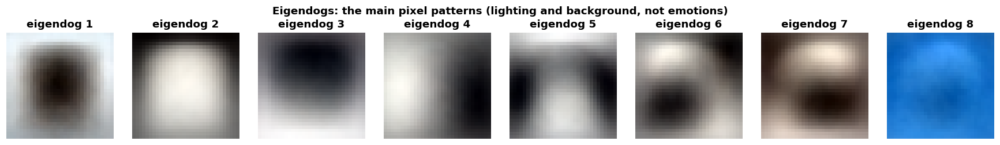

In [26]:
from sklearn.decomposition import PCA
pca = PCA(n_components=min(50, len(tr) - 1), random_state=SEED).fit(X32[tr]); Z = pca.transform(X32[te])
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for i, l in enumerate(LABELS):
    ax[0].scatter(Z[Y[te] == i, 0], Z[Y[te] == i, 1], s=5, alpha=0.45, color=COLORS[l], label=l)
ax[0].set_title("Test images on the first 2 PCA directions"); ax[0].legend(markerscale=3)
ax[1].plot(np.cumsum(pca.explained_variance_ratio_) * 100, marker="."); ax[1].set_title("% of information kept by PCA")
ax[1].set_xlabel("components")
plt.tight_layout(); plt.show()
fig, ax = plt.subplots(1, 8, figsize=(16, 2.3))
for i, a in enumerate(ax):
    c = pca.components_[i].reshape(32, 32, 3); a.imshow((c - c.min()) / (c.max() - c.min())); a.set_title(f"eigendog {i+1}"); a.axis("off")
plt.suptitle("Eigendogs: the main pixel patterns (lighting and background, not emotions)", fontweight="bold"); plt.tight_layout(); plt.show()

### A small CNN from scratch 🧠
A **convolutional neural network** slides small learnable filters over the image: first edges and colors, then parts (eyes, ears), then concepts. Nobody designs the filters: they are learned.

⏩ TinyCNN (from scratch) [before]: already trained, loaded from Drive
💾 123_tinycnn_from_scratch_before_loss.png


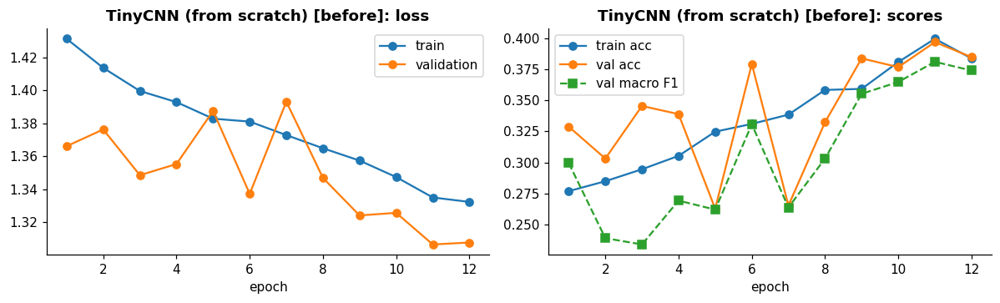

In [27]:
models_before = {}
name = "TinyCNN (from scratch) [before]"
mk, ep, lr, size, bs = DEEP["TinyCNN (from scratch)"]
models_before["TinyCNN (from scratch)"] = train(mk, name, "before", ep, lr, size, bs)
plot_history(name)

💾 124_32_learned_first_layer_filters_edge_and_color_detectors.png


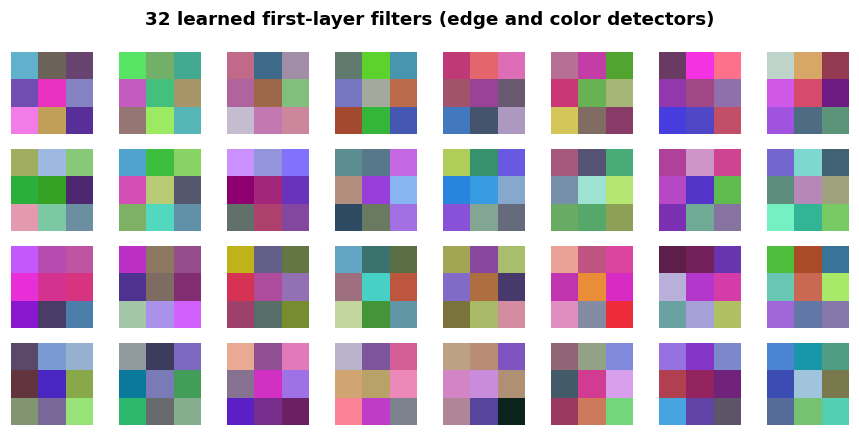

💾 125_feature_maps_layer_1_sees_edges_layer_2_sees_bigger_patterns.png


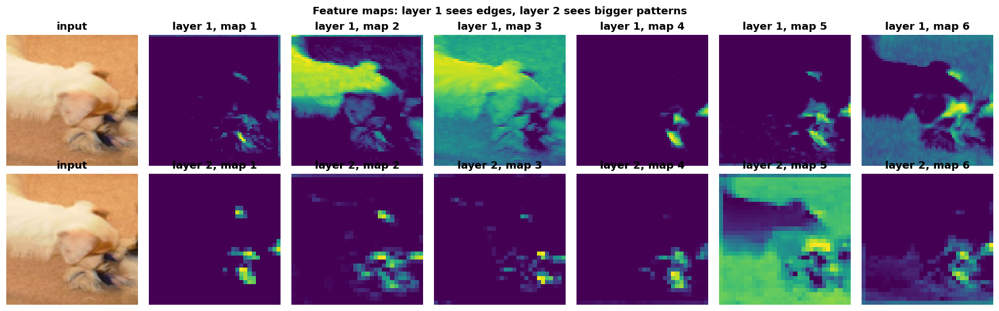

In [28]:
tiny = models_before["TinyCNN (from scratch)"]
w = tiny.features[0][0].weight.detach().cpu(); w = (w - w.min()) / (w.max() - w.min())
fig, ax = plt.subplots(4, 8, figsize=(8, 4))
for i, a in enumerate(ax.ravel()): a.imshow(w[i].permute(1, 2, 0)); a.axis("off")
plt.suptitle("32 learned first-layer filters (edge and color detectors)", fontweight="bold"); plt.tight_layout(); plt.show()
x = make_tf(128)(Image.open(PATHS[te[0]]).convert("RGB")).unsqueeze(0).to(DEVICE); tiny.eval()
with torch.no_grad():
    f1_ = tiny.features[0](x)[0].cpu(); f2_ = tiny.features[1](tiny.features[0](x))[0].cpu()
fig, ax = plt.subplots(2, 7, figsize=(16, 5))
for r, (fm, ln) in enumerate([(f1_, "layer 1"), (f2_, "layer 2")]):
    ax[r, 0].imshow(denorm(x[0].cpu())); ax[r, 0].set_title("input")
    for j in range(6): ax[r, j + 1].imshow(fm[j], cmap="viridis"); ax[r, j + 1].set_title(f"{ln}, map {j+1}")
for a in ax.ravel(): a.axis("off")
plt.suptitle("Feature maps: layer 1 sees edges, layer 2 sees bigger patterns", fontweight="bold"); plt.tight_layout(); plt.show()

### Transfer learning: borrowing a bigger brain 🎓
Models pretrained on **ImageNet** (1.2 million photos, ~120 dog breeds) already know fur, eyes and ears. Two ways to reuse them:
1. **Frozen:** use the network as a fixed "feature machine" + a simple logistic regression on top (fast);
2. **Fine-tuning:** retrain the whole network gently on our emotions.

| Model | Idea |
|---|---|
| **ResNet-50** (2015) | Deep CNN with shortcut connections |
| **EfficientNet-B0** (2019) | Small CNN scaled smartly |
| **ViT** (2020) | Cuts the image into 16×16 patches and uses *attention*: every patch looks at every other patch |

In [29]:
FEAT_FILE = OUT / "resnet50_features.npz"          # frozen features are computed once and reused
@torch.no_grad()
def extract(idx):
    fx = timm.create_model("resnet50", pretrained=PRETRAINED, num_classes=0).to(DEVICE).eval()
    dl = DataLoader(DS(idx, make_tf(224)), batch_size=BS * 2, num_workers=2); out = []
    for x, _ in tqdm(dl, desc="frozen ResNet-50 features", leave=False):
        with torch.autocast(DEVICE.type, enabled=DEVICE.type == "cuda"):
            out.append(fx(x.to(DEVICE)).float().cpu())
    del fx; torch.cuda.empty_cache(); return torch.cat(out).numpy()
t0 = time.time()
if FEAT_FILE.exists():
    z = np.load(FEAT_FILE); F_tr, F_va, F_te = z["tr"], z["va"], z["te"]; print("⏩ features loaded from Drive")
else:
    F_tr, F_va, F_te = extract(tr), extract(va), extract(te); np.savez(FEAT_FILE, tr=F_tr, va=F_va, te=F_te)
feat_time = time.time() - t0

def run_frozen(stage, mask=None):
    m = np.ones(len(tr), bool) if mask is None else mask
    t = time.time()
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, C=0.5, class_weight="balanced")).fit(F_tr[m], Y[tr][m])
    record(f"ResNet50 frozen + LogReg [{stage}]", "transfer (frozen)", stage, clf.predict_proba(F_te), feat_time + time.time() - t,
           val_f1=f1_score(Y[va], clf.predict(F_va), average="macro"), extra=dict(train_images=int(m.sum())))
run_frozen("before")
print("Each image is now described by", F_tr.shape[1], "learned features.")

⏩ features loaded from Drive
✅ ResNet50 frozen + LogReg [before]          test acc 0.439 | macro F1 0.414 | angry F1 0.23
Each image is now described by 2048 learned features.


💾 126_t_sne_of_raw_pixels.png


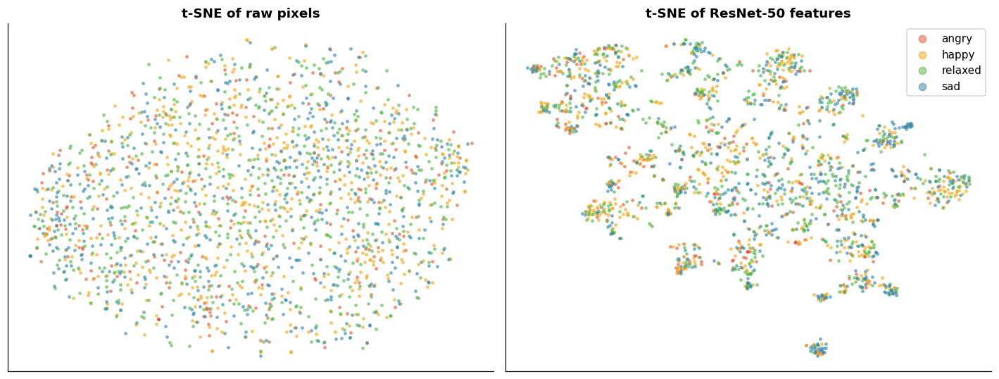

In [30]:
from sklearn.manifold import TSNE
n = min(2000, len(te)); sel = np.random.RandomState(SEED).choice(len(te), n, replace=False)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for k, (feat, title) in enumerate([(X32[te][sel], "raw pixels"), (F_te[sel], "ResNet-50 features")]):
    emb = TSNE(2, perplexity=max(5, min(30, n // 4)), init="pca", random_state=SEED).fit_transform(PCA(min(50, n - 1, feat.shape[1])).fit_transform(feat))
    for i, l in enumerate(LABELS):
        m = Y[te][sel] == i; ax[k].scatter(emb[m, 0], emb[m, 1], s=5, alpha=0.5, color=COLORS[l], label=l)
    ax[k].set_title(f"t-SNE of {title}"); ax[k].set_xticks([]); ax[k].set_yticks([])
ax[1].legend(markerscale=3); plt.tight_layout(); plt.show()

💾 127_t_sne_cluster_0_what_do_these_dogs_have_in_common.png


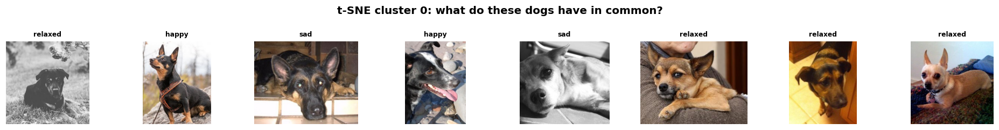

💾 128_t_sne_cluster_1_what_do_these_dogs_have_in_common.png


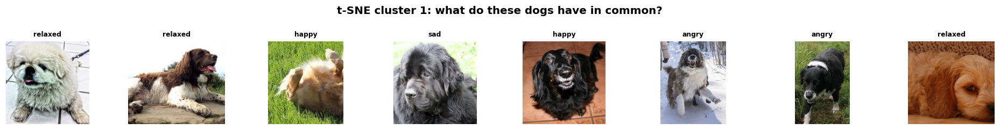

💾 129_t_sne_cluster_2_what_do_these_dogs_have_in_common.png


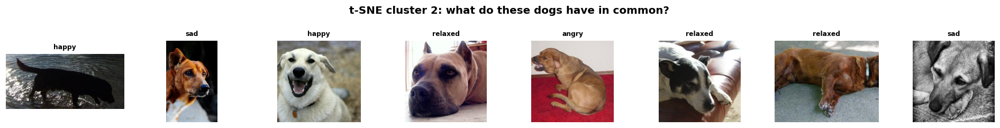

💾 130_t_sne_cluster_3_what_do_these_dogs_have_in_common.png


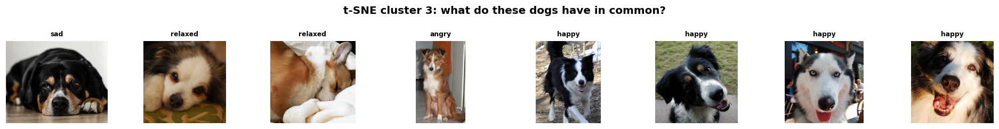

In [31]:
# What do the ResNet clusters have in common? (often breed, pose or background, not emotion)
from sklearn.cluster import KMeans
km = KMeans(min(8, n), random_state=SEED, n_init=10).fit(emb)      # emb = the ResNet t-SNE map
paths_sel, y_sel = PATHS[te][sel], Y[te][sel]
for k in range(min(4, km.n_clusters)):
    idx = np.where(km.labels_ == k)[0][:8]
    show_grid(list(paths_sel[idx]), titles=[LABELS[i] for i in y_sel[idx]], ncols=8,
              suptitle=f"t-SNE cluster {k}: what do these dogs have in common?")

➡️ Pixels: soup. ResNet features: **clusters appear**, but they mix emotions (they group breeds, poses, backgrounds). Frozen ImageNet features know *what* is in the photo, not the *emotion*, which is why we fine-tune.

### Fine-tuning ResNet-50, EfficientNet-B0 and ViT (~25 minutes) ☕

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

⏩ ResNet50 fine-tuned [before]: already trained, loaded from Drive
💾 131_resnet50_fine_tuned_before_loss.png


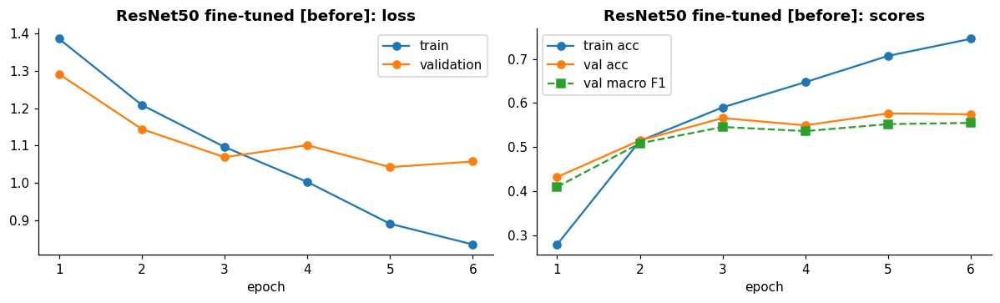

model.safetensors: reconstructing file:   0%|          |  0.00B / 21.4MB            

model.safetensors: downloading bytes:           |  0.00B            

⏩ EfficientNet-B0 fine-tuned [before]: already trained, loaded from Drive
💾 132_efficientnet_b0_fine_tuned_before_loss.png


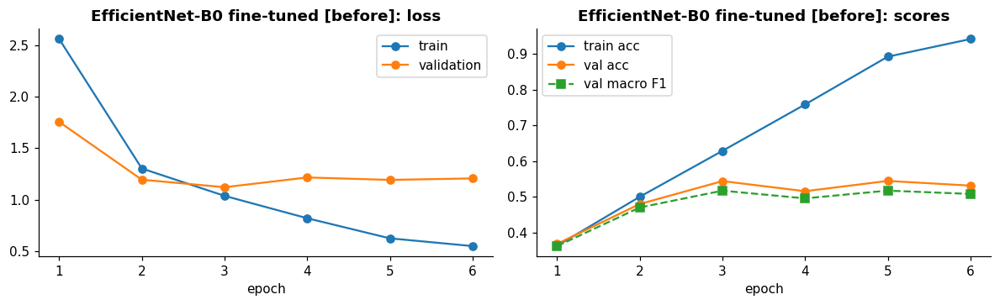

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

⏩ ViT fine-tuned [before]: already trained, loaded from Drive
💾 133_vit_fine_tuned_before_loss.png


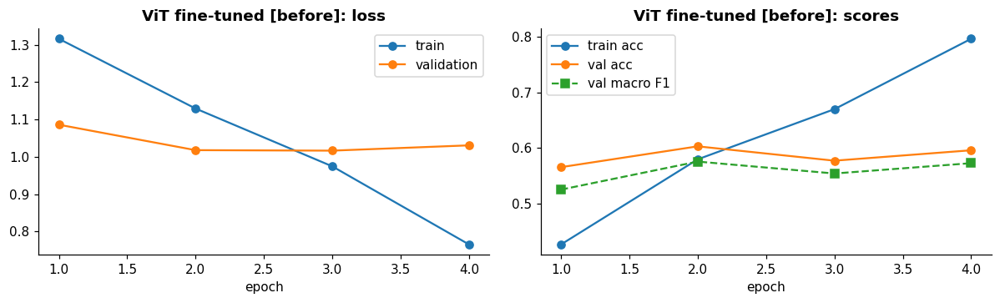

In [32]:
for base in ["ResNet50 fine-tuned", "EfficientNet-B0 fine-tuned", "ViT fine-tuned"]:
    mk, ep, lr, size, bs = DEEP[base]
    models_before[base] = train(mk, f"{base} [before]", "before", ep, lr, size, bs)
    plot_history(f"{base} [before]")
    if base != "ResNet50 fine-tuned":                 # keep ResNet in memory (Grad-CAM, TTA test); free the others
        del models_before[base]; torch.cuda.empty_cache()

## 🏁 Scoreboard BEFORE optimisation

💾 134_macro_f1_on_the_test_set_before.png


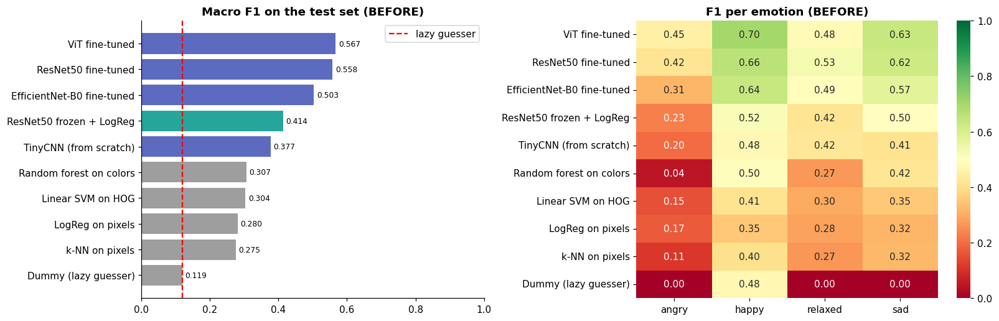

,base,family,accuracy,macro_f1,f1_angry,f1_happy,f1_relaxed,f1_sad,train_time_s
0,ViT fine-tuned,deep learning,0.590,0.567,0.452,0.700,0.481,0.634,419.386
1,ResNet50 fine-tuned,deep learning,0.579,0.558,0.418,0.659,0.531,0.624,466.250
2,EfficientNet-B0 fine-tuned,deep learning,0.538,0.503,0.313,0.636,0.493,0.572,451.347
3,ResNet50 frozen + LogReg,transfer (frozen),0.439,0.414,0.227,0.517,0.415,0.497,31.760
4,TinyCNN (from scratch),deep learning,0.396,0.377,0.197,0.479,0.423,0.411,441.328
5,Random forest on colors,classic ML,0.388,0.307,0.043,0.495,0.268,0.420,12.497
6,Linear SVM on HOG,classic ML,0.329,0.304,0.154,0.412,0.295,0.353,77.293
7,LogReg on pixels,classic ML,0.293,0.280,0.172,0.353,0.283,0.315,70.354
8,k-NN on pixels,classic ML,0.314,0.275,0.110,0.403,0.265,0.321,0.751
9,Dummy (lazy guesser),classic ML,0.313,0.119,0.000,0.476,0.000,0.000,0.139


In [33]:
def results_df(stage):
    return pd.DataFrame(RESULTS).query("stage == @stage").sort_values("macro_f1", ascending=False).reset_index(drop=True)
FAM_COL = {"classic ML": "#9e9e9e", "deep learning": "#5C6BC0", "transfer (frozen)": "#26A69A"}

def scoreboard(stage):
    r = results_df(stage).sort_values("macro_f1")
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw=dict(width_ratios=[1, 1.1]))
    b = ax[0].barh(r.base, r.macro_f1, color=[FAM_COL[f] for f in r.family]); ax[0].bar_label(b, fmt="%.3f", padding=3, fontsize=8)
    dummy = r.loc[r.base.str.startswith("Dummy"), "macro_f1"]
    if len(dummy): ax[0].axvline(dummy.iloc[0], color="red", ls="--", label="lazy guesser")
    ax[0].set_xlim(0, 1); ax[0].set_title(f"Macro F1 on the test set ({stage.upper()})"); ax[0].legend()
    sns.heatmap(r.set_index("base")[[f"f1_{l}" for l in LABELS]].iloc[::-1].rename(columns=lambda c: c[3:]), annot=True, fmt=".2f",
                cmap="RdYlGn", vmin=0, vmax=1, ax=ax[1]); ax[1].set_title(f"F1 per emotion ({stage.upper()})"); ax[1].set_ylabel("")
    plt.tight_layout(); plt.show()
    return results_df(stage)[["base", "family", "accuracy", "macro_f1"] + [f"f1_{l}" for l in LABELS] + ["train_time_s"]]

before = scoreboard("before"); before.round(3)

,base,family,accuracy,macro_f1,train_time_s,params,f1_angry,f1_happy,f1_relaxed,f1_sad
0,ViT fine-tuned,deep learning,0.590,0.567,419,"85,801,732",0.45,0.70,0.48,0.63
1,ResNet50 fine-tuned,deep learning,0.579,0.558,466,"23,516,228",0.42,0.66,0.53,0.62
2,EfficientNet-B0 fine-tuned,deep learning,0.538,0.503,451,"4,012,672",0.31,0.64,0.49,0.57
3,ResNet50 frozen + LogReg,transfer (frozen),0.439,0.414,32,-,0.23,0.52,0.42,0.50
4,TinyCNN (from scratch),deep learning,0.396,0.377,441,"390,404",0.20,0.48,0.42,0.41
5,Random forest on colors,classic ML,0.388,0.307,12,-,0.04,0.50,0.27,0.42
6,Linear SVM on HOG,classic ML,0.329,0.304,77,-,0.15,0.41,0.30,0.35
7,LogReg on pixels,classic ML,0.293,0.280,70,-,0.17,0.35,0.28,0.32
8,k-NN on pixels,classic ML,0.314,0.275,1,-,0.11,0.40,0.27,0.32
9,Dummy (lazy guesser),classic ML,0.313,0.119,0,-,0.00,0.48,0.00,0.00


💾 135_is_the_extra_effort_worth_it_before.png


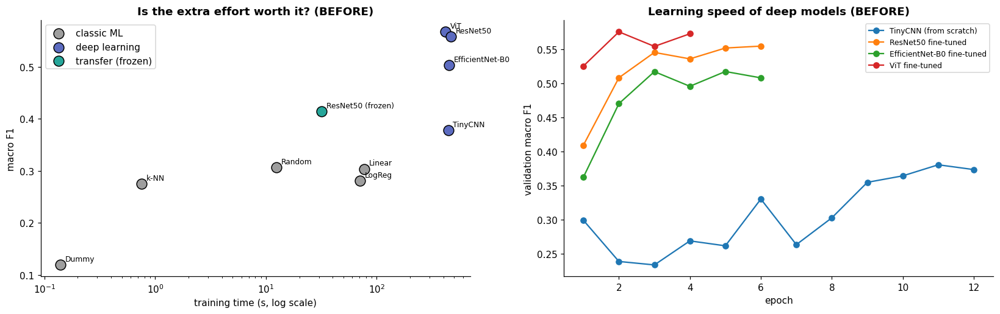

In [34]:
from IPython.display import display
def full_comparison(stage):
    res = results_df(stage)
    display(res[["base", "family", "accuracy", "macro_f1", "train_time_s", "params"] + [f"f1_{l}" for l in LABELS]].style.format(
        {"accuracy": "{:.3f}", "macro_f1": "{:.3f}", "train_time_s": "{:.0f}", "params": "{:,.0f}", **{f"f1_{l}": "{:.2f}" for l in LABELS}},
        na_rep="-").background_gradient(subset=["macro_f1"], cmap="Greens"))
    fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
    for f, c in FAM_COL.items():
        d = res[res.family == f]
        ax[0].scatter(d.train_time_s.clip(lower=0.1), d.macro_f1, s=120, color=c, label=f, edgecolor="k")
    for _, row in res.iterrows():
        ax[0].annotate(row.base.split(" ")[0] + (" (frozen)" if "frozen" in row.base else ""), (max(row.train_time_s, 0.1), row.macro_f1),
                       fontsize=8, xytext=(5, 4), textcoords="offset points")
    ax[0].set_xscale("log"); ax[0].set_xlabel("training time (s, log scale)"); ax[0].set_ylabel("macro F1")
    ax[0].set_title(f"Is the extra effort worth it? ({stage.upper()})"); ax[0].legend()
    for base in DEEP:
        h = hist_of(f"{base} [{stage}]"); ax[1].plot(h.epoch, h.val_f1, "o-", label=base)
    ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation macro F1"); ax[1].set_title(f"Learning speed of deep models ({stage.upper()})"); ax[1].legend(fontsize=8)
    plt.tight_layout(); plt.show()
full_comparison("before")

💾 136_before_the_4_best_models_who_gets_confused_with_whom.png


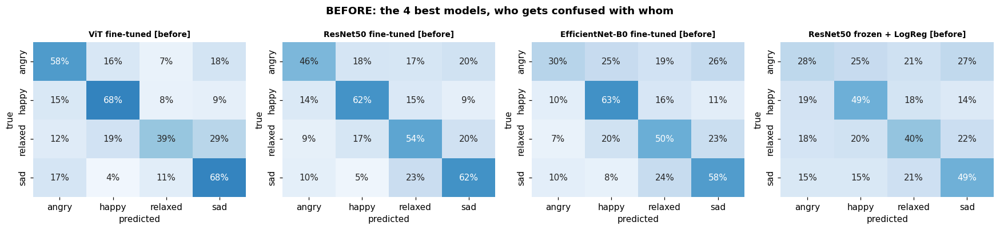

In [35]:
top_before = results_df("before").model.tolist()[:4]
plot_cms(top_before, title="BEFORE: the 4 best models, who gets confused with whom")
raw_csv = OUT.parent / "results.csv"            # Part 2 results on RAW data, if available
if raw_csv.exists():
    raw = pd.read_csv(raw_csv).set_index("model")["macro_f1"].rename("raw data (Part 2)")
    cmp_raw = pd.concat([raw, before.set_index("base")["macro_f1"].rename("clean data")], axis=1).dropna()
    if len(cmp_raw):
        ax = cmp_raw.sort_values("clean data").plot.barh(color=["#cccccc", "#5C6BC0"], figsize=(9, 4.5), width=0.75)
        ax.set_xlim(0, 1); ax.set_xlabel("test macro F1"); ax.set_title("Raw data vs clean data (different test sets: read with care)")
        plt.tight_layout(); plt.show()

⚠️ **Raw vs clean** uses **different test sets** (the clean one has no cats and no tiny dogs, so it's a bit easier). A higher score means "better data *and* an easier exam".

From now on, **BEFORE (clean data) is our reference.**

# Act B — HOW: optimising the data 🔧

We test 4 ideas. Each one targets a problem we **saw** in the results:

| Problem we saw | Data optimisation |
|---|---|
| Confident "mistakes" that were really **wrong labels** (statue, dog in a vet cone labelled angry…) | **B1. Find and remove suspicious training labels** |
| **Angry** is the smallest class and the hardest emotion | **B2. Balanced sampling**: show angry dogs as often as the others |
| **Overfitting**: train accuracy keeps climbing, validation stays flat | **B3. Stronger augmentation** |
| Predictions are sensitive to small changes | **B4. Test-time augmentation** (mirror trick) |

🧪 **Rule:** we decide what to keep using the **validation** set only. The test set is never used to make choices.

## B1. Finding wrong labels with "confident learning" 🔎
Farah's hash found **identical** photos with two labels. But some photos have one single **wrong** label. To find them without checking 9,000 photos by hand:
1. Describe each training photo with the frozen ResNet-50 features (already computed).
2. Split the training set into 5 parts; train a simple classifier on 4 parts and predict the 5th, so **every photo is judged by a model that never saw it** (*cross-validation*).
3. If that model gives a **very low probability to the photo's own label** while being confident about another emotion → **suspicious**.
4. Remove suspicious photos from **training only**. Validation and test are not touched.

Suspicious training labels: 741 of 9266 (8.0%)
💾 137_most_labels_look_plausible_a_small_tail_looks_wrong.png


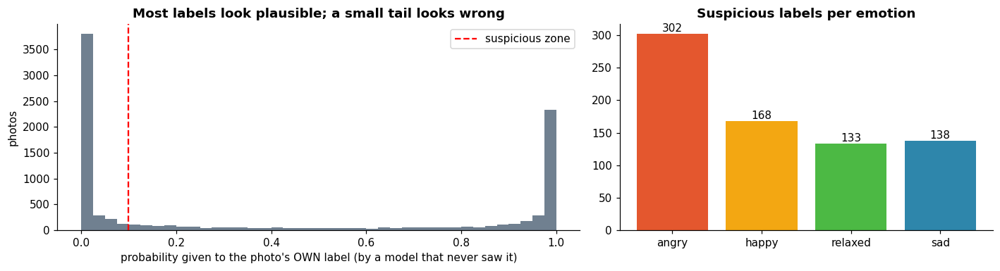

💾 138_most_suspicious_training_labels_would_you_agree_with_the_label.png


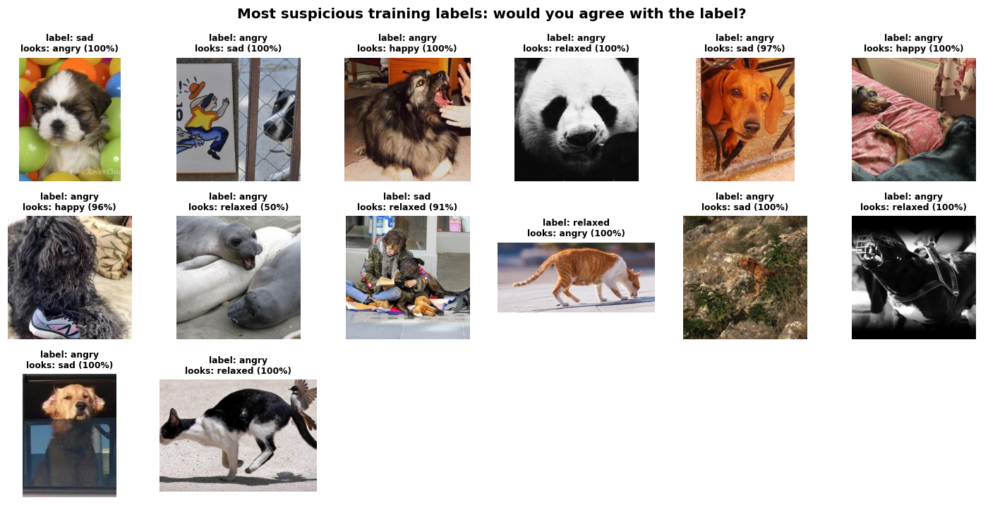

In [36]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, C=0.5, class_weight="balanced"))
oof = cross_val_predict(clf, F_tr, Y[tr], cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")
p_given = oof[np.arange(len(tr)), Y[tr]]
other = oof.copy(); other[np.arange(len(tr)), Y[tr]] = 0
suspicious = (p_given < 0.10) & (other.max(1) > 0.60)
cap = int(0.08 * len(tr))                         # never remove more than 8% of the training set
if suspicious.sum() > cap:
    suspicious[:] = False; suspicious[np.argsort(p_given)[:cap]] = True
removed = pd.Series(Y[tr][suspicious]).map(dict(enumerate(LABELS))).value_counts().reindex(LABELS, fill_value=0)
print(f"Suspicious training labels: {suspicious.sum()} of {len(tr)} ({suspicious.mean():.1%})")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw=dict(width_ratios=[1.4, 1]))
ax[0].hist(p_given, bins=40, color="slategray"); ax[0].axvline(0.10, color="red", ls="--", label="suspicious zone")
ax[0].set_xlabel("probability given to the photo's OWN label (by a model that never saw it)"); ax[0].set_ylabel("photos")
ax[0].set_title("Most labels look plausible; a small tail looks wrong"); ax[0].legend()
b = ax[1].bar(LABELS, removed, color=PALETTE); ax[1].bar_label(b); ax[1].set_title("Suspicious labels per emotion")
plt.tight_layout(); plt.show()
k = np.where(suspicious)[0][np.argsort(p_given[suspicious])][:14]
show_grid([PATHS[tr[j]] for j in k], [f"label: {LABELS[Y[tr[j]]]}\nlooks: {LABELS[oof[j].argmax()]} ({oof[j].max():.0%})" for j in k],
          suptitle="Most suspicious training labels: would you agree with the label?")
pd.DataFrame(dict(path=data.path.values[tr][suspicious], label=[LABELS[i] for i in Y[tr][suspicious]],
                  looks_like=[LABELS[i] for i in oof[suspicious].argmax(1)], p_label=p_given[suspicious].round(3))
             ).sort_values("p_label").to_csv(TAB_DIR / "suspicious_training_labels.csv", index=False)
tr_filtered = tr[~suspicious]

## B2. Balanced sampling ⚖️
Before, we used **class weights**: angry dogs were rare in each batch, but each mistake on them "cost" more. With a **balanced sampler**, rare photos are **drawn more often**, so each batch has about 25% of each emotion (repeated angry photos get different augmentations each time).

💾 139_what_the_model_sees_during_one_epoch.png


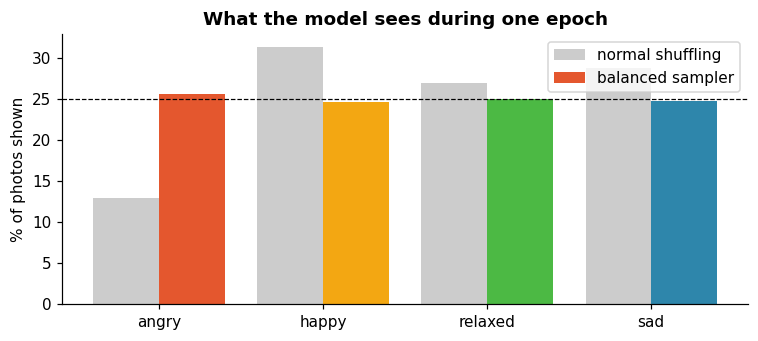

In [37]:
ytr = Y[tr]; cnt = np.bincount(ytr, minlength=4)
s = WeightedRandomSampler(torch.tensor(1.0 / cnt[ytr], dtype=torch.double), 5000, replacement=True, generator=torch.Generator().manual_seed(SEED))
drawn = np.bincount(ytr[list(s)], minlength=4)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(np.arange(4) - 0.2, cnt / cnt.sum() * 100, 0.4, color="#cccccc", label="normal shuffling")
ax.bar(np.arange(4) + 0.2, drawn / drawn.sum() * 100, 0.4, color=PALETTE, label="balanced sampler")
ax.axhline(25, ls="--", color="k", lw=0.8); ax.set_xticks(range(4), LABELS); ax.set_ylabel("% of photos shown")
ax.set_title("What the model sees during one epoch"); ax.legend(); plt.tight_layout(); plt.show()

## B3. Stronger augmentation 🎨
**TrivialAugment** applies one random transformation per image (rotation, shear, contrast, sharpness, posterize…) at a random strength. **Random erasing** hides a small rectangle, so the model must use **several** clues: if the mouth is hidden, look at the ears and eyes.

💾 140_same_photo_basic_vs_strong_augmentation.png


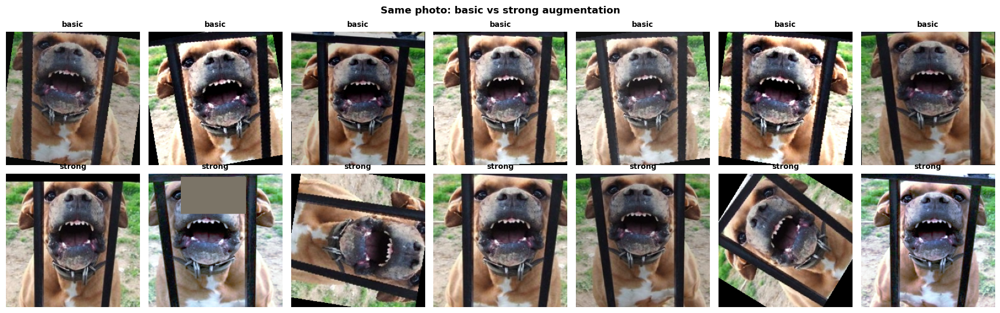

In [38]:
pil = Image.open(PATHS[tr[0]]).convert("RGB")
fig, ax = plt.subplots(2, 7, figsize=(17, 5.4))
for j in range(7):
    ax[0, j].imshow(denorm(make_tf(224, "basic")(pil))); ax[0, j].set_title("basic", fontsize=9)
    ax[1, j].imshow(denorm(make_tf(224, "strong")(pil))); ax[1, j].set_title("strong", fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.suptitle("Same photo: basic vs strong augmentation", fontweight="bold"); plt.tight_layout(); plt.show()

## B4. Test-time augmentation (TTA) 🪞
No retraining: at prediction time we show each photo **twice** (normal + mirrored) and average the answers. A dog's emotion doesn't change in a mirror, so averaging removes a little randomness. We test it on the ResNet-50 already trained.

In [40]:
import torch
print("Device:", DEVICE, "| GPU available:", torch.cuda.is_available())

Device: cpu | GPU available: False


In [41]:
import pandas as pd
from pathlib import Path
OUT = Path("/content/drive/MyDrive/dogs part 2 jamila/final_clean")
print("Saved models:", sorted(p.name for p in (OUT / "models").glob("*.pt")))

Saved models: ['abl_balanced_sampler_ablation.pt', 'abl_label_filtering_ablation.pt', 'abl_plain_ablation.pt', 'abl_strong_augmentation_ablation.pt', 'efficientnet_b0_fine_tuned_after.pt', 'efficientnet_b0_fine_tuned_before.pt', 'resnet50_fine_tuned_after.pt', 'resnet50_fine_tuned_before.pt', 'tinycnn_from_scratch_after.pt', 'tinycnn_from_scratch_before.pt', 'vit_fine_tuned_after.pt', 'vit_fine_tuned_before.pt']


In [42]:
import pandas as pd
from pathlib import Path
OUT = Path("/content/drive/MyDrive/dogs part 2 jamila/final_clean")
(OUT / "models" / "abl_label_filtering_ablation.pt").unlink(missing_ok=True)
r = pd.read_csv(OUT / "all_results.csv")
r[r.model != "ABL + label filtering [ablation]"].to_csv(OUT / "all_results.csv", index=False)
print("Old filtering run removed")

Old filtering run removed


Suspicious training labels: 461 of 9266 (5.0%)
💾 141_label_check_with_a_careful_judge_fixed_version.png


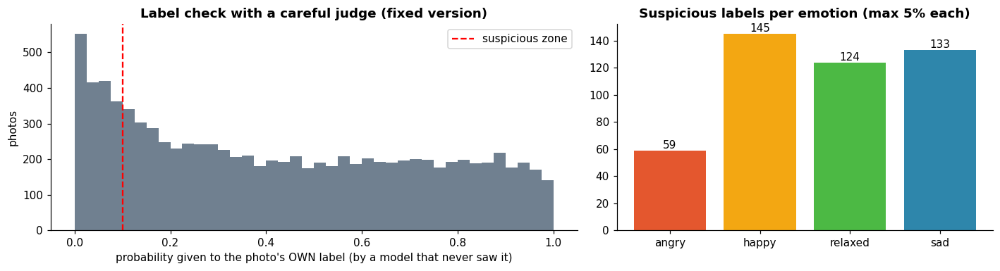

💾 142_most_suspicious_training_labels_would_you_agree_with_the_label.png


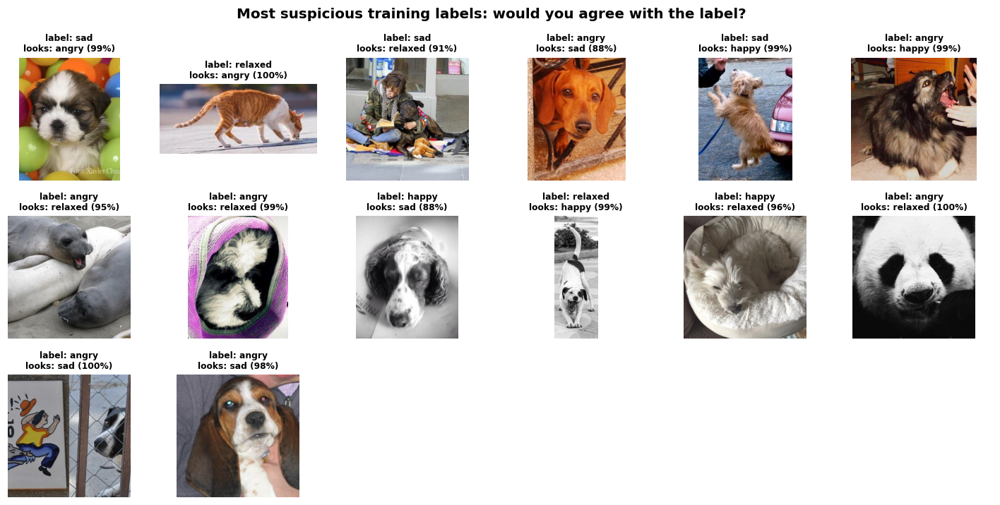

In [43]:
from sklearn.model_selection import cross_val_predict, StratifiedKFold
# Fixed version: a more careful judge (strong regularisation) + at most 5% removed per emotion
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.005, class_weight="balanced"))
oof = cross_val_predict(clf, F_tr, Y[tr], cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method="predict_proba")
p_given = oof[np.arange(len(tr)), Y[tr]]
other = oof.copy(); other[np.arange(len(tr)), Y[tr]] = 0
suspicious = (p_given < 0.10) & (other.max(1) > 0.60)
for c in range(4):                                # never remove more than 5% of ANY emotion (protects angry)
    in_c = np.where(Y[tr] == c)[0]
    cap_c = int(0.05 * len(in_c))
    flagged = in_c[suspicious[in_c]]
    if len(flagged) > cap_c:
        keep_flag = flagged[np.argsort(p_given[flagged])[:cap_c]]
        suspicious[flagged] = False; suspicious[keep_flag] = True
removed = pd.Series(Y[tr][suspicious]).map(dict(enumerate(LABELS))).value_counts().reindex(LABELS, fill_value=0)
print(f"Suspicious training labels: {suspicious.sum()} of {len(tr)} ({suspicious.mean():.1%})")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw=dict(width_ratios=[1.4, 1]))
ax[0].hist(p_given, bins=40, color="slategray"); ax[0].axvline(0.10, color="red", ls="--", label="suspicious zone")
ax[0].set_xlabel("probability given to the photo's OWN label (by a model that never saw it)"); ax[0].set_ylabel("photos")
ax[0].set_title("Label check with a careful judge (fixed version)"); ax[0].legend()
b = ax[1].bar(LABELS, removed, color=PALETTE); ax[1].bar_label(b); ax[1].set_title("Suspicious labels per emotion (max 5% each)")
plt.tight_layout(); plt.show()
k = np.where(suspicious)[0][np.argsort(p_given[suspicious])][:14]
show_grid([PATHS[tr[j]] for j in k], [f"label: {LABELS[Y[tr[j]]]}\nlooks: {LABELS[oof[j].argmax()]} ({oof[j].max():.0%})" for j in k],
          suptitle="Most suspicious training labels: would you agree with the label?")
pd.DataFrame(dict(path=data.path.values[tr][suspicious], label=[LABELS[i] for i in Y[tr][suspicious]],
                  looks_like=[LABELS[i] for i in oof[suspicious].argmax(1)], p_label=p_given[suspicious].round(3))
             ).sort_values("p_label").to_csv(TAB_DIR / "suspicious_training_labels.csv", index=False)
tr_filtered = tr[~suspicious]

In [39]:
rn = models_before["ResNet50 fine-tuned"]
v_plain = f1_score(Y[va], predict(rn, va).argmax(1), average="macro")
v_tta = f1_score(Y[va], predict(rn, va, tta=True).argmax(1), average="macro")
USE_TTA = v_tta > v_plain + 0.002
print(f"ResNet-50 validation macro F1: {v_plain:.3f} → with TTA {v_tta:.3f}  ⇒ keep TTA: {USE_TTA}")

KeyboardInterrupt: 

## B5. Which ideas really help? An ablation test 🧪
An **ablation** changes **one thing at a time**. We train ResNet-50 (shorter, a few epochs) 4 times: plain, with filtered labels, with balanced sampling, with strong augmentation. A change is **kept** if it raises the **validation** macro F1 by at least 0.005 (smaller differences can be luck).

In [ ]:
mk_rn = DEEP["ResNet50 fine-tuned"][0]; E = EPOCHS["ablation"]
ABL = {"ABL plain": dict(), "ABL + label filtering": dict(train_idx=tr_filtered),
       "ABL + balanced sampler": dict(balance="sampler"), "ABL + strong augmentation": dict(aug="strong")}
for name, kw in ABL.items():
    m = train(mk_rn, f"{name} [ablation]", "ablation", E, 5e-4, **kw); del m; torch.cuda.empty_cache()

ab = pd.DataFrame(RESULTS).query("stage == 'ablation'").set_index("base")
base_val = ab.loc["ABL plain", "val_macro_f1"]
KEEP = dict(filter=ab.loc["ABL + label filtering", "val_macro_f1"] > base_val + 0.005,
            sampler=ab.loc["ABL + balanced sampler", "val_macro_f1"] > base_val + 0.005,
            strong=ab.loc["ABL + strong augmentation", "val_macro_f1"] > base_val + 0.005, tta=USE_TTA)
o = ab.loc[list(ABL)]
fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
c = ["#9e9e9e"] + ["#43A047" if KEEP[k] else "#E57373" for k in ["filter", "sampler", "strong"]]
b = ax[0].barh(o.index[::-1], o.val_macro_f1[::-1] - base_val, color=c[::-1]); ax[0].axvline(0, color="k", lw=0.8)
ax[0].axvline(0.005, color="gray", ls=":", label="keep threshold"); ax[0].bar_label(b, fmt="%+.3f", padding=3, fontsize=8)
ax[0].set_title("Change in VALIDATION macro F1 vs plain (decides)"); ax[0].legend(fontsize=8)
sns.heatmap(o[[f"f1_{l}" for l in LABELS]].rename(columns=lambda c: c[3:]), annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, ax=ax[1])
ax[1].set_title("Test F1 per emotion (for the report)"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()
RECIPE = dict(train_idx=tr_filtered if KEEP["filter"] else tr, balance="sampler" if KEEP["sampler"] else "weights",
              aug="strong" if KEEP["strong"] else "basic", tta=KEEP["tta"])
print("✅ Optimised data recipe:", {k: ("YES" if v else "no") for k, v in KEEP.items()})
json.dump({k: bool(v) for k, v in KEEP.items()}, open(OUT / "optimised_recipe.json", "w"), indent=2)

➡️ Green = kept, red = dropped. If **no** idea passes the threshold, that's a valid result too: it means the clean data was already the main win, and we say so in the report.

# Act C — AFTER: all 10 models with the optimised data 🚀
Same models, same settings, same test set. Only the data recipe changes:
- **classic ML** and the **frozen ResNet**: trained without the suspicious labels (if label filtering was kept). Augmentation and sampling don't apply to them;
- **deep networks**: the full recipe (filtered labels, sampling, augmentation and TTA, whichever were kept).

In [44]:
mask_after = ~suspicious if KEEP["filter"] else np.ones(len(tr), bool)
run_classic("after", tr[mask_after])
run_frozen("after", mask_after)
models_after = {}
for base in ["TinyCNN (from scratch)", "ResNet50 fine-tuned", "EfficientNet-B0 fine-tuned", "ViT fine-tuned"]:
    mk, ep, lr, size, bs = DEEP[base]
    models_after[base] = train(mk, f"{base} [after]", "after", ep, lr, size, bs, **RECIPE)
    plot_history(f"{base} [after]")
    if base not in ("ResNet50 fine-tuned",):
        del models_after[base]; torch.cuda.empty_cache()
after = scoreboard("after"); after.round(3)

NameError: name 'KEEP' is not defined

In [ ]:
full_comparison("after")
plot_cms(results_df("after").model.tolist()[:4], title="AFTER: the 4 best models, who gets confused with whom")

# Act D — BEFORE vs AFTER 📊
The moment of truth: the same 10 models, before and after optimising the data, on the **same test set**.

In [ ]:
B = results_df("before").set_index("base"); A = results_df("after").set_index("base")
cmp = pd.DataFrame({"family": B.family, "F1 before": B.macro_f1, "F1 after": A.macro_f1,
                    "angry F1 before": B.f1_angry, "angry F1 after": A.f1_angry}).dropna(subset=["F1 after"])
cmp["Δ F1"] = cmp["F1 after"] - cmp["F1 before"]; cmp["Δ angry"] = cmp["angry F1 after"] - cmp["angry F1 before"]
cmp = cmp.sort_values("F1 after"); cmp.round(3).to_csv(TAB_DIR / "before_vs_after.csv")

fig, ax = plt.subplots(1, 2, figsize=(16, 5.2), gridspec_kw=dict(width_ratios=[1.2, 1]))
y = np.arange(len(cmp))
ax[0].hlines(y, cmp["F1 before"], cmp["F1 after"], color="#bbb", lw=3)
ax[0].scatter(cmp["F1 before"], y, color="#9e9e9e", s=70, label="before", zorder=3)
ax[0].scatter(cmp["F1 after"], y, color=["#43A047" if d >= 0 else "#E53935" for d in cmp["Δ F1"]], s=90, label="after", zorder=3)
for yi, (a_, d) in enumerate(zip(cmp["F1 after"], cmp["Δ F1"])):
    ax[0].text(max(a_, cmp["F1 before"].iloc[yi]) + 0.015, yi, f"{d:+.3f}", va="center", fontsize=8, color="#2E7D32" if d >= 0 else "#C62828")
ax[0].set_yticks(y, cmp.index); ax[0].set_xlim(0, 1); ax[0].set_xlabel("test macro F1"); ax[0].legend(loc="lower right")
ax[0].set_title("Every model, before → after data optimisation")
delta = (A[[f"f1_{l}" for l in LABELS]] - B[[f"f1_{l}" for l in LABELS]]).loc[cmp.index[::-1]].rename(columns=lambda c: c[3:])
lim = max(0.05, float(np.nanmax(np.abs(delta.values))))
sns.heatmap(delta, annot=True, fmt="+.2f", cmap="RdYlGn", center=0, vmin=-lim, vmax=lim, ax=ax[1])
ax[1].set_title("Change in F1 per emotion (green = better)"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()
cmp.round(3)

In [ ]:
best_b = results_df("before").query("family != 'classic ML'").model.iloc[0]
best_a = results_df("after").query("family != 'classic ML'").model.iloc[0]
plot_cms([best_b, best_a], ncols=2, title="Best model: confusions before vs after")

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
for a, base in zip(ax, ["ResNet50 fine-tuned", "ViT fine-tuned"]):
    for stage, st in [("before", "--"), ("after", "-")]:
        h = hist_of(f"{base} [{stage}]")
        a.plot(h.epoch, h.train_acc, st, color="#1E88E5", label=f"train acc ({stage})")
        a.plot(h.epoch, h.val_f1, st, color="#43A047", marker="o", label=f"val F1 ({stage})")
    a.set_title(f"{base}: overfitting before vs after"); a.set_xlabel("epoch"); a.legend(fontsize=7)
plt.tight_layout(); plt.show()

In [ ]:
# Three stages for the report: raw data (Part 2) → clean data → clean + optimised
if raw_csv.exists():
    raw = pd.read_csv(raw_csv).set_index("model")["macro_f1"]
    three = pd.DataFrame({"1. raw data": raw, "2. clean data": B.macro_f1, "3. clean + optimised": A.macro_f1}).dropna()
    if len(three):
        ax = three.loc[cmp.index.intersection(three.index)].plot.barh(color=["#cccccc", "#9FA8DA", "#3949AB"], figsize=(10, 5.5), width=0.8)
        ax.set_xlim(0, 1); ax.set_xlabel("test macro F1"); ax.set_title("The full journey: raw → clean → optimised (stage 1 used another test set)")
        plt.tight_layout(); plt.show(); three.round(3).to_csv(TAB_DIR / "raw_clean_optimised.csv")

## Explainability: did the model's attention change? 🔍
**Grad-CAM** colors the regions that pushed the model to its answer (red = "this convinced me"). We compare ResNet-50 **before** and **after** on the same test photos: after optimisation, does it look more at the face and less at the background?

In [ ]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        self.h = layer.register_forward_hook(self._hook)
    def _hook(self, m, i, out):
        self.acts = out
        if out.requires_grad: out.register_hook(lambda g: setattr(self, "grads", g))
    def __call__(self, x):
        self.model.eval(); self.model.zero_grad(); out = self.model(x); c = out.argmax(1).item(); out[0, c].backward()
        cam = F.relu((self.grads.mean(dim=(2, 3), keepdim=True) * self.acts).sum(1))[0].detach().cpu().numpy()
        return cam / (cam.max() + 1e-8), c, out.softmax(1)[0].detach().cpu().numpy()
    def remove(self): self.h.remove()

rb, ra = models_before["ResNet50 fine-tuned"].float(), models_after["ResNet50 fine-tuned"].float()
cams = {"before": GradCAM(rb, rb.layer4[-1]), "after": GradCAM(ra, ra.layer4[-1])}
yb, ya = probs_of("ResNet50 fine-tuned [before]").argmax(1), probs_of("ResNet50 fine-tuned [after]").argmax(1)
fixed = [te[k] for k in range(len(te)) if yb[k] != Y[te][k] and ya[k] == Y[te][k]][:3]
pick = fixed + [next(te[k] for k in range(len(te)) if Y[te][k] == c) for c in range(4)]
pick = list(dict.fromkeys(pick))[:7]
fig, ax = plt.subplots(3, len(pick), figsize=(2.5 * len(pick), 7.6), squeeze=False)
for j, i in enumerate(pick):
    pil = Image.open(PATHS[i]).convert("RGB"); x = make_tf(224)(pil).unsqueeze(0).to(DEVICE)
    base = np.asarray(pil.resize((224, 224))) / 255
    ax[0, j].imshow(base); ax[0, j].set_title(f"true: {LABELS[Y[i]]}" + ("\n(fixed by optimisation)" if i in fixed else ""), fontsize=8)
    for r, st in enumerate(["before", "after"], start=1):
        cam, c, p = cams[st](x)
        heat = np.asarray(Image.fromarray(np.uint8(cam * 255)).resize((224, 224), Image.BILINEAR)) / 255
        ax[r, j].imshow(base); ax[r, j].imshow(heat, cmap="jet", alpha=0.45)
        ax[r, j].set_title(f"{st}: {LABELS[c]} ({p[c]:.0%})", fontsize=8, color="green" if c == Y[i] else "red")
for a in ax.ravel(): a.axis("off")
plt.suptitle("Grad-CAM, ResNet-50: where does it look, before vs after?", fontweight="bold"); plt.tight_layout(); plt.show()
for g_ in cams.values(): g_.remove()

In [ ]:
# Grad-CAM grids: correct predictions and mistakes, for the best CNN before and after
def show_cams(model, model_name, indices, title):
    gc = GradCAM(model, model.layer4[-1] if hasattr(model, "layer4") else model.conv_head)
    fig, ax = plt.subplots(2, len(indices), figsize=(2.6 * len(indices), 5.6), squeeze=False)
    for j, i in enumerate(indices):
        pil = Image.open(PATHS[i]).convert("RGB"); x = make_tf(224)(pil).unsqueeze(0).to(DEVICE)
        cam, c, p = gc(x)
        base = np.asarray(pil.resize((224, 224))) / 255
        heat = np.asarray(Image.fromarray(np.uint8(cam * 255)).resize((224, 224), Image.BILINEAR)) / 255
        ax[0, j].imshow(base); ax[0, j].set_title(f"true: {LABELS[Y[i]]}", fontsize=9)
        ax[1, j].imshow(base); ax[1, j].imshow(heat, cmap="jet", alpha=0.45)
        ax[1, j].set_title(f"pred: {LABELS[c]} ({p[c]:.0%})", fontsize=9, color="green" if c == Y[i] else "red")
    for a in ax.ravel(): a.axis("off")
    plt.suptitle(f"{model_name}: {title}", fontweight="bold"); plt.tight_layout(); plt.show(); gc.remove()

for stage in ["before", "after"]:
    cnn = max(["ResNet50 fine-tuned", "EfficientNet-B0 fine-tuned"], key=lambda b: results_df(stage).set_index("base").loc[b, "macro_f1"])
    m, _ = load_trained(cnn, stage); m = m.float()
    yp = probs_of(f"{cnn} [{stage}]").argmax(1)
    right = [te[k] for k in range(len(te)) if yp[k] == Y[te][k]]
    right_per_class = [next((i for i in right if Y[i] == c), right[0]) for c in range(4)] if right else []
    right_per_class += [i for i in right if i not in right_per_class][:2]
    if right_per_class: show_cams(m, f"{cnn} [{stage}]", right_per_class, "correct predictions, does it look at the face and body?")
    wrong = [te[k] for k in range(len(te)) if yp[k] != Y[te][k]][:6]
    if wrong: show_cams(m, f"{cnn} [{stage}]", wrong, "mistakes, what fooled it?")
    del m; torch.cuda.empty_cache()

➡️ **Good sign:** red on the eyes, mouth, ears and body. **Bad sign:** red on the background, a watermark or a toy: a *shortcut*. Compare before and after.

## Error analysis and calibration 🧐
The mistakes the best model makes **with high confidence** often point to wrong labels in the **test** set (we never clean the test set, to keep the exam honest). And calibration checks whether "80% sure" really means "right 80% of the time".

In [ ]:
P = probs_of(best_a); pred, conf = P.argmax(1), P.max(1)
err = pd.DataFrame(dict(path=data.path.values[te], small=PATHS[te], true=[LABELS[i] for i in Y[te]], pred=[LABELS[i] for i in pred], confidence=conf))
sus = err[err.true != err.pred].sort_values("confidence", ascending=False)
sus.drop(columns="small").head(100).round(3).to_csv(TAB_DIR / "suspicious_test_labels.csv", index=False)
top = sus.head(14)
show_grid(top.small.tolist(), [f"label: {t}\nmodel: {p} ({c:.0%})" for t, p, c in zip(top.true, top.pred, top.confidence)],
          suptitle=f"{best_a}: most confident mistakes. Wrong model or wrong label?")

Pb = probs_of(best_b)
errb = pd.DataFrame(dict(small=PATHS[te], true=[LABELS[i] for i in Y[te]], pred=[LABELS[i] for i in Pb.argmax(1)], confidence=Pb.max(1)))
susb = errb[errb.true != errb.pred].sort_values("confidence", ascending=False).head(14)
show_grid(susb.small.tolist(), [f"label: {t}\nmodel: {p} ({c:.0%})" for t, p, c in zip(susb.true, susb.pred, susb.confidence)],
          suptitle=f"{best_b}: most confident mistakes (BEFORE)")
n90b = int(((Pb.argmax(1) != Y[te]) & (Pb.max(1) > 0.9)).sum()); n90a = int(((pred != Y[te]) & (conf > 0.9)).sum())
print(f"Mistakes made with >90% confidence: before {n90b} | after {n90a}")
print(f"Saved the 100 most suspicious test images to {TAB_DIR / 'suspicious_test_labels.csv'} (send it to Farah!)")

fig, ax = plt.subplots(figsize=(5.5, 4.8)); ax.plot([0, 1], [0, 1], "k--", label="perfectly honest")
for n_, col in [(best_b, "#9e9e9e"), (best_a, "#3949AB")]:
    Pn = probs_of(n_); cf, pr = Pn.max(1), Pn.argmax(1); bins = np.linspace(0.25, 1, 8); mids, accs = [], []
    for lo, hi in zip(bins[:-1], bins[1:]):
        m = (cf >= lo) & (cf < hi)
        if m.sum(): mids.append(cf[m].mean()); accs.append((pr[m] == Y[te][m]).mean())
    ax.plot(mids, accs, "o-", color=col, label=n_)
ax.set_xlabel("model confidence"); ax.set_ylabel("actual accuracy"); ax.set_title("Calibration: is the confidence honest?"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

# 🎬 DogTranslator: the final model in action
The best optimised model + a **dog gate**: a standard ImageNet ResNet first checks that there *is* a dog (ImageNet classes 151–268 are dog breeds). Without it, a cat photo would still get an "emotion" because our models only know 4 answers.

In [ ]:
final_base = results_df("after").query("family == 'deep learning'").sort_values("val_macro_f1", ascending=False).base.iloc[0]   # chosen on VALIDATION
mk, ep, lr, FINAL_SIZE, bs = DEEP[final_base]
final = mk().to(DEVICE); final.load_state_dict(torch.load(MODEL_DIR / f"{_key(final_base + ' [after]')}.pt", map_location=DEVICE)); final.eval()
gate = timm.create_model("resnet50", pretrained=PRETRAINED).to(DEVICE).eval()
print("Final model (best validation F1 after optimisation):", final_base)

CAPTIONS = {"angry": ["Back. Off. This is MY sock.", "I have chosen violence today.", "Touch the bowl. I dare you."],
            "happy": ["Did someone say WALK?!", "Best. Day. EVER.", "I love you. I love everyone. I love this stick."],
            "relaxed": ["I am RELAXED. Do not disturb the nap.", "Peak comfort achieved.", "Currently in power-saving mode."],
            "sad": ["You left for 5 minutes. It felt like 5 years.", "No treat? I see how it is.", "The vet. You took me to the vet."]}
TIPS = {"angry": "Give space: stiff body, bared teeth, hard stare = warning signs.", "happy": "Loose body, open mouth, wagging tail: a good moment to play.",
        "relaxed": "Soft eyes, lying down: let sleeping dogs lie.", "sad": "Low ears and head: check if something is wrong, comfort gently."}

@torch.no_grad()
def translate(pil):
    x = make_tf(224)(pil).unsqueeze(0).to(DEVICE)
    p_dog = gate(x).softmax(1)[0, 151:269].sum().item()
    xf = make_tf(FINAL_SIZE)(pil).unsqueeze(0).to(DEVICE)
    p = final(xf).softmax(1)
    if RECIPE["tta"]: p = (p + final(torch.flip(xf, dims=[3])).softmax(1)) / 2
    return p_dog, p[0].cpu().numpy()

def show_translation(pils, titles):
    fig, ax = plt.subplots(2, len(pils), figsize=(3.3 * len(pils), 6), gridspec_kw=dict(height_ratios=[3, 1]), squeeze=False)
    for j, (pil, t) in enumerate(zip(pils, titles)):
        p_dog, p = translate(pil); lab = LABELS[p.argmax()]; ax[0, j].imshow(pil); ax[0, j].axis("off"); ax[0, j].set_title(t[:28], fontsize=8)
        msg = random.choice(CAPTIONS[lab]) if p_dog >= 0.5 or TEST else "No dog detected. DogTranslator only speaks Dog."
        ax[0, j].text(0.5, 0.03, msg, transform=ax[0, j].transAxes, ha="center", va="bottom", fontsize=8.5, color="white",
                      fontweight="bold", wrap=True, bbox=dict(facecolor="black" if p_dog >= 0.5 or TEST else "#B71C1C", alpha=0.7, pad=4))
        ax[1, j].barh(LABELS, p, color=PALETTE); ax[1, j].set_xlim(0, 1); ax[1, j].set_title(f"{lab} ({p.max():.0%}) | dog {p_dog:.0%}", fontsize=8)
    plt.tight_layout(); plt.show()

idx = np.random.RandomState(7).choice(te, 5, replace=False)
show_translation([Image.open(PATHS[i]).convert("RGB") for i in idx], [f"true: {LABELS[Y[i]]}" for i in idx])

In [ ]:
# 📸 Try your own photos (dogs, cats, memes...). iPhone HEIC photos work too.
!pip install -q pillow-heif
from pillow_heif import register_heif_opener
register_heif_opener()
try:
    from google.colab import files
    up = files.upload()                       # click "Choisir les fichiers"
except ImportError:
    up = {}; print("Upload works in Colab only.")
for fname in up:
    try:
        img = ImageOps.exif_transpose(Image.open(fname)).convert("RGB")
        safe = f"upload_{Path(fname).stem}.jpg"; img.save(safe)
        show_translation([img], [fname])
        p_dog, p = translate(img); lab = LABELS[p.argmax()]
        print(f"🐶 {lab.upper()} ({p.max():.0%} sure) | dog detected: {p_dog:.0%}")
        print("   " + " | ".join(f"{l} {v:.0%}" for l, v in zip(LABELS, p)))
        print("💡 Tip:", TIPS[lab])
    except Exception as e:
        print(f"❌ {fname}: {type(e).__name__}: {e}")

In [ ]:
# 🌍 Optional: free test photos from Wikimedia Commons (same breed, different emotions + Darwin's 1872 drawing)
import requests, io
TEST_DOGS = {"A_Beagle_snarling.jpg": "angry", "A_Beagle_sitting_with_her_tongue_out.jpg": "happy",
             "A_Beagle_sleeping_on_a_carpet.jpg": "relaxed", "A_Beagle_sleeping_on_the_beach.jpg": "relaxed",
             "Fawn_and_white_Welsh_Corgi_puppy_standing_on_rear_legs_and_sticking_out_the_tongue.jpg": "happy",
             "2008-07-11_White_German_Shepherd_pup_chilling_at_the_Coker_Arboretum.jpg": "relaxed",
             "Expression_of_the_Emotions_Figure_14.png": "angry (Darwin's drawing)"}
Path("test_dogs").mkdir(exist_ok=True)
for fname, human in TEST_DOGS.items():
    try:
        r = requests.get(f"https://commons.wikimedia.org/wiki/Special:FilePath/{fname}?width=800",
                         headers={"User-Agent": "DogTranslator student project"}, timeout=30); r.raise_for_status()
        Image.open(io.BytesIO(r.content)).convert("RGB").save(Path("test_dogs") / fname.replace(".png", ".jpg"))
    except Exception as e:
        print("❌ skipped", fname, "→", e)
from glob import glob
wiki = sorted(glob("test_dogs/*.jpg"))
if wiki: show_translation([Image.open(p).convert("RGB") for p in wiki], [Path(p).stem for p in wiki])

In [ ]:
# 🩺 Quick check (if a cell seems stuck: is the GPU there, are the photos there?)
import torch
from glob import glob
print("GPU:", torch.cuda.is_available())
print("trained models on Drive:", len(list(MODEL_DIR.glob("*.pt"))))
print("photos:", glob("upload_*.jpg") + glob("test_dogs/*.jpg"))

In [ ]:
# 🧹 Remove duplicate uploads (the same file uploaded twice becomes "... (2).jpg")
import os, re
from glob import glob
photos_all = sorted(glob("upload_*.jpg"))
dups = [p for p in photos_all if re.search(r"\(\d+\)\.jpg$", p)]
for p in dups: os.remove(p)
print(f"Removed {len(dups)} duplicates. Kept {len(glob('upload_*.jpg'))} uploads + {len(glob('test_dogs/*.jpg'))} Wikimedia photos.")

### Same photos, every model, before and after 🆚
Each row is one model; green title if they all agree. If the strong models disagree, the photo is genuinely ambiguous (hidden face, meme, unusual pose).

In [ ]:
from glob import glob
@torch.no_grad()
def predict_with(model, size, pil):
    return model(make_tf(size)(pil).unsqueeze(0).to(DEVICE)).float().softmax(1)[0].cpu().numpy()
CMP_MODELS = {}
for base in DEEP:
    for stage in ["before", "after"]:
        CMP_MODELS[f"{base.split(' ')[0]} {stage}"] = load_trained(base, stage)
photos = sorted(glob("upload_*.jpg")) + sorted(glob("test_dogs/*.jpg"))
if not photos: photos = list(PATHS[np.random.RandomState(3).choice(te, 3, replace=False)])
rows = []
for path in photos:
    pil = Image.open(path).convert("RGB")
    probs = np.stack([predict_with(m, s, pil) for m, s in CMP_MODELS.values()])
    preds = [LABELS[i] for i in probs.argmax(1)]
    agree = len(set(preds)) == 1
    for n_, p in zip(CMP_MODELS, probs):
        rows.append(dict(photo=Path(path).stem, model=n_, prediction=LABELS[p.argmax()], confidence=p.max(), **dict(zip(LABELS, p))))
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw=dict(width_ratios=[1, 1.6]))
    ax[0].imshow(pil); ax[0].axis("off")
    sns.heatmap(probs, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax[1],
                xticklabels=LABELS, yticklabels=[f"{n_}: {p}" for n_, p in zip(CMP_MODELS, preds)])
    ax[1].set_title("all models agree ✓" if agree else "models disagree ✗", color="green" if agree else "red")
    plt.suptitle(Path(path).stem[:50], fontweight="bold"); plt.tight_layout(); plt.show()
cmp_photos = pd.DataFrame(rows); cmp_photos.round(3).to_csv(TAB_DIR / "models_on_new_photos.csv", index=False)
table = cmp_photos.pivot(index="photo", columns="model", values="prediction")[list(CMP_MODELS)]
table["agreement"] = table.nunique(axis=1).map(lambda k: "✓ all agree" if k == 1 else f"✗ {k} different answers")
del CMP_MODELS; torch.cuda.empty_cache()
table

# 💾 Save everything for the team

In [ ]:
json.dump(dict(model_name={"TinyCNN (from scratch)": "TinyCNN", "ResNet50 fine-tuned": "resnet50", "EfficientNet-B0 fine-tuned": "efficientnet_b0",
                           "ViT fine-tuned": VIT_NAME}[final_base],
               weights=f"models/{_key(final_base + ' [after]')}.pt", labels=LABELS, image_size=FINAL_SIZE, normalize_mean=MEAN, normalize_std=STD,
               tta_horizontal_flip=bool(RECIPE["tta"]), dog_gate="timm resnet50 ImageNet, sum of classes 151-268 >= 0.5",
               data_recipe={k: bool(v) for k, v in KEEP.items()}), open(OUT / "FINAL_model_card.json", "w"), indent=2)
summary = dict(n_images_raw=int(len(df)), n_images_clean=int(len(data)), split_sizes=dict(train=len(tr), val=len(va), test=len(te)),
               raw_counts=RAW_COUNTS.to_dict(), clean_counts=clean_counts.to_dict(), suspicious_removed=int(suspicious.sum()),
               data_recipe={k: bool(v) for k, v in KEEP.items()}, best_before=best_b, best_after=best_a, final_model=final_base)
json.dump(summary, open(OUT / "summary.json", "w"), indent=2, default=float)
allres = pd.DataFrame(RESULTS)
with pd.ExcelWriter(TAB_DIR / "all_tables.xlsx") as xl:
    allres.round(4).to_excel(xl, sheet_name="all_results", index=False)
    for st in ["before", "after", "ablation"]:
        allres.query("stage == @st").round(4).to_excel(xl, sheet_name=st, index=False)
    cmp.round(4).to_excel(xl, sheet_name="before_vs_after")
    tab.assign(total=tab.sum(1)).to_excel(xl, sheet_name="split_sizes")
    removed.rename("suspicious_removed").to_frame().to_excel(xl, sheet_name="label_filtering")
print("✅ Saved in", OUT)
print("   models/ · figures/ · tables/ (all_tables.xlsx) · all_results.csv · FINAL_model_card.json · optimised_recipe.json")

# 🧩 Appendix: use the trained models later WITHOUT a GPU
If Colab refuses the GPU, connect without GPU and run **only this cell** (in this notebook or a new one). It reloads the 4 networks (before **or** after) from Drive and compares them on photos you upload. CPU is enough: 1–3 seconds per photo.

In [ ]:
# ==== DogTranslator: reload the trained models from Drive (works WITHOUT GPU) and compare them on uploaded photos ====
!pip install -q timm pillow-heif
import random, numpy as np, torch, torch.nn as nn, timm, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from PIL import Image, ImageOps
from torchvision import transforms
from pillow_heif import register_heif_opener; register_heif_opener()

STAGE = "after"                                   # "before" or "after" data optimisation
try:
    from google.colab import drive, files
    drive.mount("/content/drive")
    MODELS_DIR = Path("/content/drive/MyDrive/dogs part 2 jamila/final_clean/models")
except ImportError:
    MODELS_DIR = OUT / "models"; files = None
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
LABELS = ["angry", "happy", "relaxed", "sad"]
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
CAPTIONS = {"angry": ["Back. Off. This is MY sock.", "I have chosen violence today.", "Touch the bowl. I dare you."],
            "happy": ["Did someone say WALK?!", "Best. Day. EVER.", "I love you. I love everyone. I love this stick."],
            "relaxed": ["I am RELAXED. Do not disturb the nap.", "Peak comfort achieved.", "Currently in power-saving mode."],
            "sad": ["You left for 5 minutes. It felt like 5 years.", "No treat? I see how it is.", "The vet. You took me to the vet."]}
TIPS = {"angry": "Give space: stiff body, bared teeth, hard stare = warning signs.",
        "happy": "Loose body, open mouth, wagging tail: a good moment to play.",
        "relaxed": "Soft eyes, lying down: let sleeping dogs lie.",
        "sad": "Low ears and head: check if something is wrong, comfort gently."}

class TinyCNN(nn.Module):                       # same architecture as above
    def __init__(self, n=4):
        super().__init__()
        def block(i, o): return nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), block(128, 256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, n))
    def forward(self, x): return self.head(self.features(x))

SPECS = {"ViT": (VIT_NAME if "VIT_NAME" in globals() else "vit_base_patch16_224", f"vit_fine_tuned_{STAGE}.pt", 224),
         "ResNet50": ("resnet50", f"resnet50_fine_tuned_{STAGE}.pt", 224),
         "EfficientNet": ("efficientnet_b0", f"efficientnet_b0_fine_tuned_{STAGE}.pt", 224),
         "TinyCNN": ("tiny", f"tinycnn_from_scratch_{STAGE}.pt", 128)}
MODELS = {}
for name, (arch, file, size) in SPECS.items():
    path = MODELS_DIR / file
    if not path.exists():
        print(f"⚠️ {name}: {file} not found in {MODELS_DIR}, skipped"); continue
    m = TinyCNN() if arch == "tiny" else timm.create_model(arch, pretrained=False, num_classes=4)
    m.load_state_dict(torch.load(path, map_location=DEV)); MODELS[name] = (m.to(DEV).eval(), size)
print("Loaded:", list(MODELS), f"({STAGE}) | device:", DEV)

@torch.no_grad()
def predict_cpu(model, size, pil):
    tf = transforms.Compose([transforms.Resize((size, size)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
    return model(tf(pil).unsqueeze(0).to(DEV)).softmax(1)[0].cpu().numpy()

def compare(pil, title):
    probs = np.stack([predict_cpu(m, s, pil) for m, s in MODELS.values()])
    preds = [LABELS[i] for i in probs.argmax(1)]
    agree = len(set(preds)) == 1
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw=dict(width_ratios=[1, 1.5]))
    ax[0].imshow(pil); ax[0].axis("off")
    ax[0].text(0.5, 0.03, random.choice(CAPTIONS[preds[0]]), transform=ax[0].transAxes, ha="center", va="bottom",
               fontsize=9, color="white", fontweight="bold", bbox=dict(facecolor="black", alpha=0.65, pad=4))
    sns.heatmap(probs, annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=ax[1],
                xticklabels=LABELS, yticklabels=[f"{n}: {p}" for n, p in zip(MODELS, preds)])
    ax[1].set_title("All models agree ✓" if agree else "Models disagree ✗", color="green" if agree else "red")
    plt.suptitle(title[:50], fontweight="bold"); plt.tight_layout(); plt.show()
    print(f"🏆 {list(MODELS)[0]} says: {preds[0].upper()} ({probs[0].max():.0%}) | Tip: {TIPS[preds[0]]}\n")

up = files.upload() if files else {}            # click "Choisir les fichiers"
for fname in up:
    try:
        compare(ImageOps.exif_transpose(Image.open(fname)).convert("RGB"), Path(fname).stem)
    except Exception as e:
        print(f"❌ {fname}: {type(e).__name__}: {e}")

### Save every image shown in this notebook (one PNG per output, named by section)
Charts are already saved automatically in `figures/`. This cell also extracts **every** image output (including uploads and tables drawn as images) straight from the notebook, and zips the whole results folder.

In [ ]:
import base64, shutil
try:
    from google.colab import _message, files
    nb = _message.blocking_request("get_ipynb", request="", timeout_sec=600)["ipynb"]
    ALL_DIR = OUT / "all_notebook_images"; ALL_DIR.mkdir(parents=True, exist_ok=True)
    section, n_img = "setup", 0
    for i, cell in enumerate(nb["cells"]):
        src = "".join(cell.get("source", ""))
        if cell["cell_type"] == "markdown":
            heads = [l.lstrip("#").strip() for l in src.splitlines() if l.startswith("#")]
            if heads: section = heads[0]
            continue
        for o in cell.get("outputs", []):
            img = o.get("data", {}).get("image/png")
            if img:
                n_img += 1; img = "".join(img) if isinstance(img, list) else img
                (ALL_DIR / f"{n_img:03d}_cell{i:02d}_{_slug(section, 'section')[:40]}.png").write_bytes(base64.b64decode(img))
    print(f"💾 {n_img} images saved to {ALL_DIR}")
    zip_path = shutil.make_archive("/content/dogtranslator_final_outputs", "zip", OUT, ".", )
    print("Zip ready:", zip_path, "(models included, so it can be big: download figures/ and tables/ from Drive instead if you prefer)")
except ImportError:
    print("This cell works in Colab only.")

# 🎓 What to write in the report (answer with your numbers)

**Act A, before:**
1. How far above the lazy guesser is each family (classic ML, frozen, fine-tuned)?
2. Which model is best on clean data, and which emotion is hardest?

**Act B, how:**
3. How many training labels looked wrong, and do the example photos convince you?
4. Which optimisations passed the validation test, and which didn't? (A "no" is a valid finding.)

**Act C/D, after:**
5. Which models gained the most from the optimised data? Classic ML only got label filtering; deep models got the full recipe. Does that show in the Δ?
6. Did **angry** improve (the Δ per emotion heatmap)?
7. Did overfitting shrink (learning curves before vs after)?
8. Does Grad-CAM look more at the face after optimisation?

**Limitations to mention:** one run per model (differences under ~0.01 may be luck); the test set still contains some wrong labels (we never clean it, to keep the exam honest); the model is closed-set (it needs the dog gate).